# Getting Started with `dynestyx` State Space Models

*This example fits the BART weekly ridership model of the [comparing inference methods](inference_methods_comparison.html) example and the ARMA model of the [ARMA](arma.html) example as [`dynestyx`](https://github.com/BasisResearch/dynestyx) state space models. It is the entry point to `dynestyx` in `numpyro_forecast`. The [advanced example](dynestyx_integration.html) continues with filtering versus smoothing, the cost of a gradient, variational inference and backtesting.*

The [`dynestyx` repository](https://github.com/BasisResearch/dynestyx) describes the library as follows:

> `dynestyx` is a library designed for Bayesian modeling and inference of dynamical systems. It is an extension of [NumPyro](https://num.pyro.ai/en/stable/), and incorporates a wide variety of state-of-the-art inference methods for state space models.

This notebook uses these components of `dynestyx`:

- **`DynamicalModel`**: holds the initial condition, the state evolution and the observation model of a state space model.
- **`dynestyx.sample`**: adds a `DynamicalModel` to a NumPyro model. The effect handlers around the call decide what it does with the model.
- **`Filter` and `Smoother`**: handlers that integrate the latent path out and add the marginal log likelihood to the NumPyro trace.
- **`LatentPathBuilder`**: a handler that samples the latent path.
- **`Simulator`**: a handler that rolls the state forward in time.

The [`state_space`](../../reference/contrib.dynestyx.state_space.html) building block of `numpyro_forecast.contrib.dynestyx` (extra `dynestyx`) connects a `DynamicalModel` to the drivers of the package: [`forecast`](../../reference/predictive.forecast.html), [`predict_in_sample`](../../reference/predictive.predict_in_sample.html), [`to_datatree`](../../reference/convert.to_datatree.html) and [`backtest`](../../reference/evaluate.backtest.html).

We proceed as follows:

1. **How `state_space` works.** The three modes of the block and where the `dynestyx` handler goes.
2. **Local level with a Kalman filter.** The BART model with Normal noise: the Kalman filter integrates the level out, and we compare the fit with the `innovations` model of the package.
3. **In-sample predictive and forecast.** We export the Kalman fit with `to_datatree` under a Kalman smoother, without a refit.
4. **Student-T noise with an explicit path.** No Kalman filter is exact here, so `dynestyx` samples the level.
5. **Missing data.** We fit the explicit-path model through a gap of $20$ weeks.
6. **A two-dimensional state.** We write ARMA(1,1) as a state space model.

## Prepare Notebook

In [1]:
import numpyro

numpyro.set_host_device_count(n=4)  # before any import that initializes jax

import warnings
from time import perf_counter
from typing import Literal

import arviz as az
import dynestyx as dsx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
import polars as pl
import xarray as xr
from dynestyx import DiscreteTimeSimulator, DynamicalModel, Filter, LatentPathBuilder, Smoother
from dynestyx.inference.configs.smoother import KFSmootherConfig
from dynestyx.inference.filters import KFConfig
from dynestyx.models import LinearGaussianObservation, LinearGaussianStateEvolution
from jax import random
from jaxtyping import Float
from numpyro.infer import MCMC, NUTS
from numpyro.infer.reparam import LocScaleReparam

from numpyro_forecast import (
    Horizon,
    eval_crps,
    forecast,
    innovations,
    predict,
    predict_in_sample,
    predictions_to_datatree,
    ssoe,
    to_datatree,
)
from numpyro_forecast.contrib.dynestyx import state_space
from numpyro_forecast.datasets import load_bart_weekly
from numpyro_forecast.features import fourier_features
from numpyro_forecast.typing import Array, ForecastModel

# arviz-plots warns whenever `aes` maps `alpha`, even to `["prob"]` as the band plots below do
warnings.filterwarnings(
    "ignore", message="When multiple credible intervals are plotted", category=UserWarning
)

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

rng_key = random.PRNGKey(seed=42)

print(f"dynestyx {dsx.__version__}, numpyro {numpyro.__version__}, jax {jax.__version__}")

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

dynestyx 0.8.0, numpyro 0.22.0, jax 0.11.2


## How `state_space` Works

`state_space(h, name, y, dynamics, controls=...)` goes inside a model function `(covariates, data=None)`, like the other building blocks of the package. It turns the [`Horizon`](../../reference/models.Horizon.html) `h` into the time grids of `dynestyx.sample`, calls it once, and registers the sites the drivers read. `h` decides the mode of the call:

- **Training** (`data` given, no horizon): the handler adds its likelihood to the trace, which is what NUTS or SVI fits.
- **Forecasting** (`covariates` longer than `data`): a `Simulator` rolls the conditioned state at the last observation forward, and the block registers the draws as the `"forecast"` site.
- **In-sample predictive** (`data=None`): the block draws the in-sample states, from the smoothing distribution under a `Smoother` or the sampled path under a `LatentPathBuilder`. It draws one observation per step from the observation model and registers them as the `"obs"` site. This is not a prior predictive, because the block still conditions on the observed window.

The block reads the observed window `y` from the covariates, as [`ssoe`](../../reference/models.ssoe.html) does, because the drivers call the model without data for the in-sample predictive.

The `dynestyx` handler goes around each call that runs the model, as in the `dynestyx` examples, so the same model function serves every inference strategy:

```python
with Filter(filter_config=KFConfig()):
    mcmc.run(key_fit, covariates_train, data_train)

# the parameters only, without the filtered states that the filter fit recorded
posterior = {k: v for k, v in mcmc.get_samples().items() if not k.startswith("f_")}
with DiscreteTimeSimulator(n_simulations=1), Smoother(smoother_config=KFSmootherConfig()):
    tree = to_datatree(key_export, model, posterior, data_train, covariates)
```

The block raises an error when no `Filter`, `Smoother` or `LatentPathBuilder` is around the call. Without one, `dynestyx` would pick an inference method itself and only log the choice.

## Local Level with a Kalman Filter

The [comparing inference methods](inference_methods_comparison.html) example fits a random walk level plus a Fourier regression to the weekly BART ridership. In this section the noise is Normal:

$$
\begin{align*}
\ell_t &= \ell_{t-1} + w_t, \qquad w_t \sim \text{Normal}(0, s), \\
y_t &= b + \ell_t + \beta^\top u_t + v_t, \qquad v_t \sim \text{Normal}(0, \sigma),
\end{align*}
$$

where $y_t$ is the log ridership of week $t$, $u_t$ holds the $52$ Fourier terms of the yearly cycle, and $s$ is the `drift_scale`. The priors are those of the comparing inference methods example. We hold out the last $52$ weeks.

The covariate array carries the series in column $0$ and the Fourier terms in columns `1:`. The `dynestyx` model reads its observed window from column $0$, and the `numpyro_forecast` model ignores it.

In [2]:
bart = load_bart_weekly()
duration = bart.shape[0]
t_obs = duration - 52
bart_train, bart_test = bart[:t_obs], bart[t_obs:]
week = np.arange(duration)

fourier = fourier_features(duration, period=365.25 / 7, num_terms=26)
bart_covariates = jnp.concatenate([bart, fourier], axis=-1)  # (duration, 53)

print(f"covariates {bart_covariates.shape}, train {bart_train.shape}, test {bart_test.shape}")

covariates (469, 53), train (417, 1), test (52, 1)


The model is linear and Gaussian, so the Kalman filter integrates the level out exactly, and NUTS explores the $55$ parameters only. In `dynestyx` terms, the regression is the control matrix `D` of the observation model and the intercept is its `bias`. The Fourier terms enter as controls over the whole horizon, so the forecast reads their future rows from the covariates.

In [3]:
def gaussian_ssm(covariates: Array, data: Array | None = None) -> None:
    """Random walk level plus Fourier regression with Normal noise, as a dynestyx model."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :1]  # the observed window, (t_obs, 1)
    controls = covariates[..., 1:]  # the Fourier terms over the whole horizon, (duration, 52)
    bias = numpyro.sample("bias", dist.Normal(0.0, 10.0))
    weight = numpyro.sample(
        "weight", dist.Normal(0.0, 0.1).expand([controls.shape[-1]]).to_event(1)
    )
    drift_scale = numpyro.sample("drift_scale", dist.LogNormal(-20.0, 5.0))
    sigma = numpyro.sample("sigma", dist.LogNormal(-5.0, 5.0))
    dynamics = DynamicalModel(
        initial_condition=dist.MultivariateNormal(jnp.zeros(1), drift_scale**2 * jnp.eye(1)),
        state_evolution=LinearGaussianStateEvolution(
            A=jnp.eye(1), cov=drift_scale**2 * jnp.eye(1)
        ),
        observation_model=LinearGaussianObservation(
            H=jnp.eye(1), R=sigma**2 * jnp.eye(1), D=weight[None, :], bias=bias[None]
        ),
        control_dim=controls.shape[-1],
    )
    state_space(h, "f", y, dynamics, controls=controls)

Next, let's render the model with `numpyro.render_model`. The render traces the model, so the block needs a `dynestyx` handler around the call. We use the Kalman filter of the fit below, on the `cd_dynamax` backend. We pass `KFConfig` explicitly: without a configuration, `Filter()` uses an ensemble Kalman filter, which is approximate.

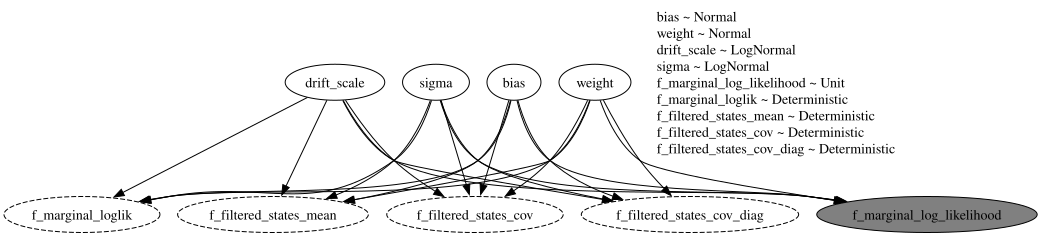

In [4]:
kalman = Filter(filter_config=KFConfig(filter_source="cd_dynamax"))

with kalman:
    graph = numpyro.render_model(
        gaussian_ssm,
        model_args=(bart_covariates[:t_obs], bart_train),
        render_distributions=True,
    )

graph

The graph has no `time` plate: the Kalman filter integrates the level out, so NUTS samples the four parameter sites only. The gray node `f_marginal_log_likelihood` is the factor that the filter adds to the trace. The dashed nodes are deterministic sites that `dynestyx` records, such as the filtered state means `f_filtered_states_mean`.

As a reference we fit the same model with the building blocks of the package: [`innovations`](../../reference/models.innovations.html) samples the $417$ weekly steps of the level, and [`predict`](../../reference/models.predict.html) adds the likelihood. The comparing inference methods example also samples a `centered` site for its `LocScaleReparam`. That site only selects a parameterization, so its posterior equals its prior and NUTS mixes poorly on it. Here we fix the non-centered form instead.

In [5]:
def gaussian_model(covariates: Array, data: Array | None = None) -> None:
    """Random walk level plus Fourier regression with Normal noise, with ``innovations``."""
    h = Horizon.from_data(covariates, data)
    fourier = covariates[..., 1:]  # column 0 is the series, read only by the dynestyx model
    bias = numpyro.sample("bias", dist.Normal(0.0, 10.0))
    weight = numpyro.sample(
        "weight", dist.Normal(0.0, 0.1).expand([fourier.shape[-1]]).to_event(1)
    )
    drift_scale = numpyro.sample("drift_scale", dist.LogNormal(-20.0, 5.0))
    sigma = numpyro.sample("sigma", dist.LogNormal(-5.0, 5.0))
    drift = innovations(
        h, "drift", dist.Normal(0.0, drift_scale), reparam=LocScaleReparam(centered=0)
    )
    level = jnp.cumsum(drift, axis=-2)
    regression = (weight * fourier).sum(axis=-1, keepdims=True)
    predict(h, dist.Normal(0.0, sigma), level + bias + regression)

This model has no `dynestyx` site, so we render it without a handler:

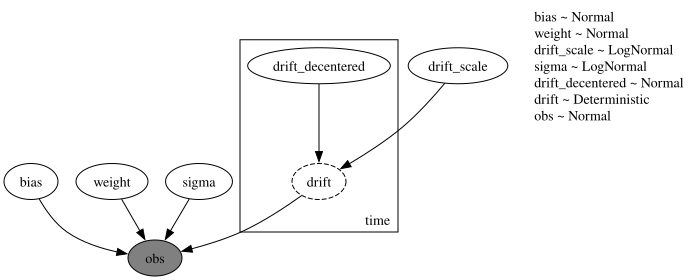

In [6]:
numpyro.render_model(
    gaussian_model,
    model_args=(bart_covariates[:t_obs], bart_train),
    render_distributions=True,
)

Here the level is explicit. The `time` plate holds the non-centered weekly steps `drift_decentered` and the steps `drift`, which enter the likelihood of the observed `obs` site.

We fit both models with NUTS: $4$ chains, a target acceptance probability of $0.9$ and parallel chains. The fits under a `LatentPathBuilder` below are the exception: they run their chains one after the other. Every fit in this notebook goes through `fit_nuts`, which also returns the wall time of the run, warmup and compilation included.

For every fit we check the convergence over every sample site, the vectors and the latent path included. `diagnostics` reports the number of scalar parameters NUTS explores, the smallest bulk effective sample size (ESS), the largest $\hat{R}$, the number of divergent transitions, the leapfrog steps per draw and the wall time. `fits_table` collects the diagnostics of several fits into one table. `posterior_tree` collects the draws of a list of sites into an ArviZ tree, which is where the diagnostics and the posterior plots below start.

In [7]:
def fit_nuts(
    rng_key: Array,
    model: ForecastModel,
    covariates: Array,
    data: Array,
    *,
    num_warmup: int,
    chain_method: Literal["parallel", "sequential", "vectorized"],
    num_samples: int = 1_000,
) -> tuple[MCMC, float]:
    """Fit ``model`` with NUTS (4 chains) and return the sampler and the wall time in seconds."""
    mcmc = MCMC(
        NUTS(model, target_accept_prob=0.9),
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=4,
        chain_method=chain_method,
        progress_bar=False,
    )
    start = perf_counter()
    mcmc.run(rng_key, covariates, data, extra_fields=("num_steps", "diverging"))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, perf_counter() - start


def posterior_tree(mcmc: MCMC, names: list[str]) -> xr.DataTree:
    """Return the ``(chain, draw)`` posterior of the sites ``names`` as a DataTree."""
    grouped = mcmc.get_samples(group_by_chain=True)
    return az.from_dict({"posterior": {name: np.asarray(grouped[name]) for name in names}})


def diagnostics(mcmc: MCMC, seconds: float) -> dict[str, int | float]:
    """Convergence over every sample site of the fit, and its sampler cost."""
    sites = sorted(mcmc.last_state.z)  # the sample sites NUTS explores, deterministic ones out
    tree = posterior_tree(mcmc, sites)
    # one value per scalar parameter; min and max propagate a NaN
    ess = np.concatenate(
        [v.to_numpy().ravel() for v in az.ess(tree, method="bulk").dataset.data_vars.values()]
    )
    r_hat = np.concatenate(
        [v.to_numpy().ravel() for v in az.rhat(tree).dataset.data_vars.values()]
    )
    extra = mcmc.get_extra_fields()
    return {
        "parameters": ess.size,
        "min bulk ESS": round(float(ess.min())),  # a NaN raises
        "max R-hat": round(float(r_hat.max()), 3),
        "divergences": int(np.asarray(extra["diverging"]).sum()),
        "leapfrog steps per draw": round(float(np.asarray(extra["num_steps"]).mean()), 1),
        "wall time (s)": round(seconds, 1),
    }


def fits_table(fits: dict[str, dict[str, int | float]]) -> pl.DataFrame:
    """One row of ``diagnostics`` per fit."""
    return pl.DataFrame([{"fit": label} | row for label, row in fits.items()])

The `dynestyx` fit runs under the Kalman filter `kalman` of the graph above.

In [8]:
rng_key, key_kalman, key_innovations = random.split(rng_key, 3)

with kalman:
    mcmc_kalman, seconds = fit_nuts(
        key_kalman,
        gaussian_ssm,
        bart_covariates[:t_obs],
        bart_train,
        num_warmup=2_000,
        chain_method="parallel",
    )

gaussian_fits = {"dynestyx Kalman filter": diagnostics(mcmc_kalman, seconds)}

mcmc_innovations, seconds = fit_nuts(
    key_innovations,
    gaussian_model,
    bart_covariates[:t_obs],
    bart_train,
    num_warmup=2_000,
    chain_method="parallel",
)
gaussian_fits["innovations"] = diagnostics(mcmc_innovations, seconds)

fits_table(gaussian_fits)

fit,parameters,min bulk ESS,max R-hat,divergences,leapfrog steps per draw,wall time (s)
str,i64,i64,f64,i64,f64,f64
"""dynestyx Kalman filter""",55,4245,1.004,0,11.5,72.5
"""innovations""",472,1684,1.008,0,127.0,11.9


Both fits converge over all their parameters:

- The largest $\hat{R}$ is $1.008$ and the smallest bulk ESS is $1{,}684$. There are no divergent transitions.
- NUTS explores $55$ parameters with the Kalman filter and $472$ with `innovations`, the $417$ weekly steps of the level included.
- The filter takes $11.5$ leapfrog steps per draw, against $127.0$ for `innovations`. Each of those steps runs the filter as a sequential scan over the $417$ weeks. That costs much more than the cumulative sum of `innovations`, so on the CPU that executed this notebook the Kalman fit took longer in wall time.

We overlay the posteriors of the three scalar parameters that both models share, one parameter per panel.

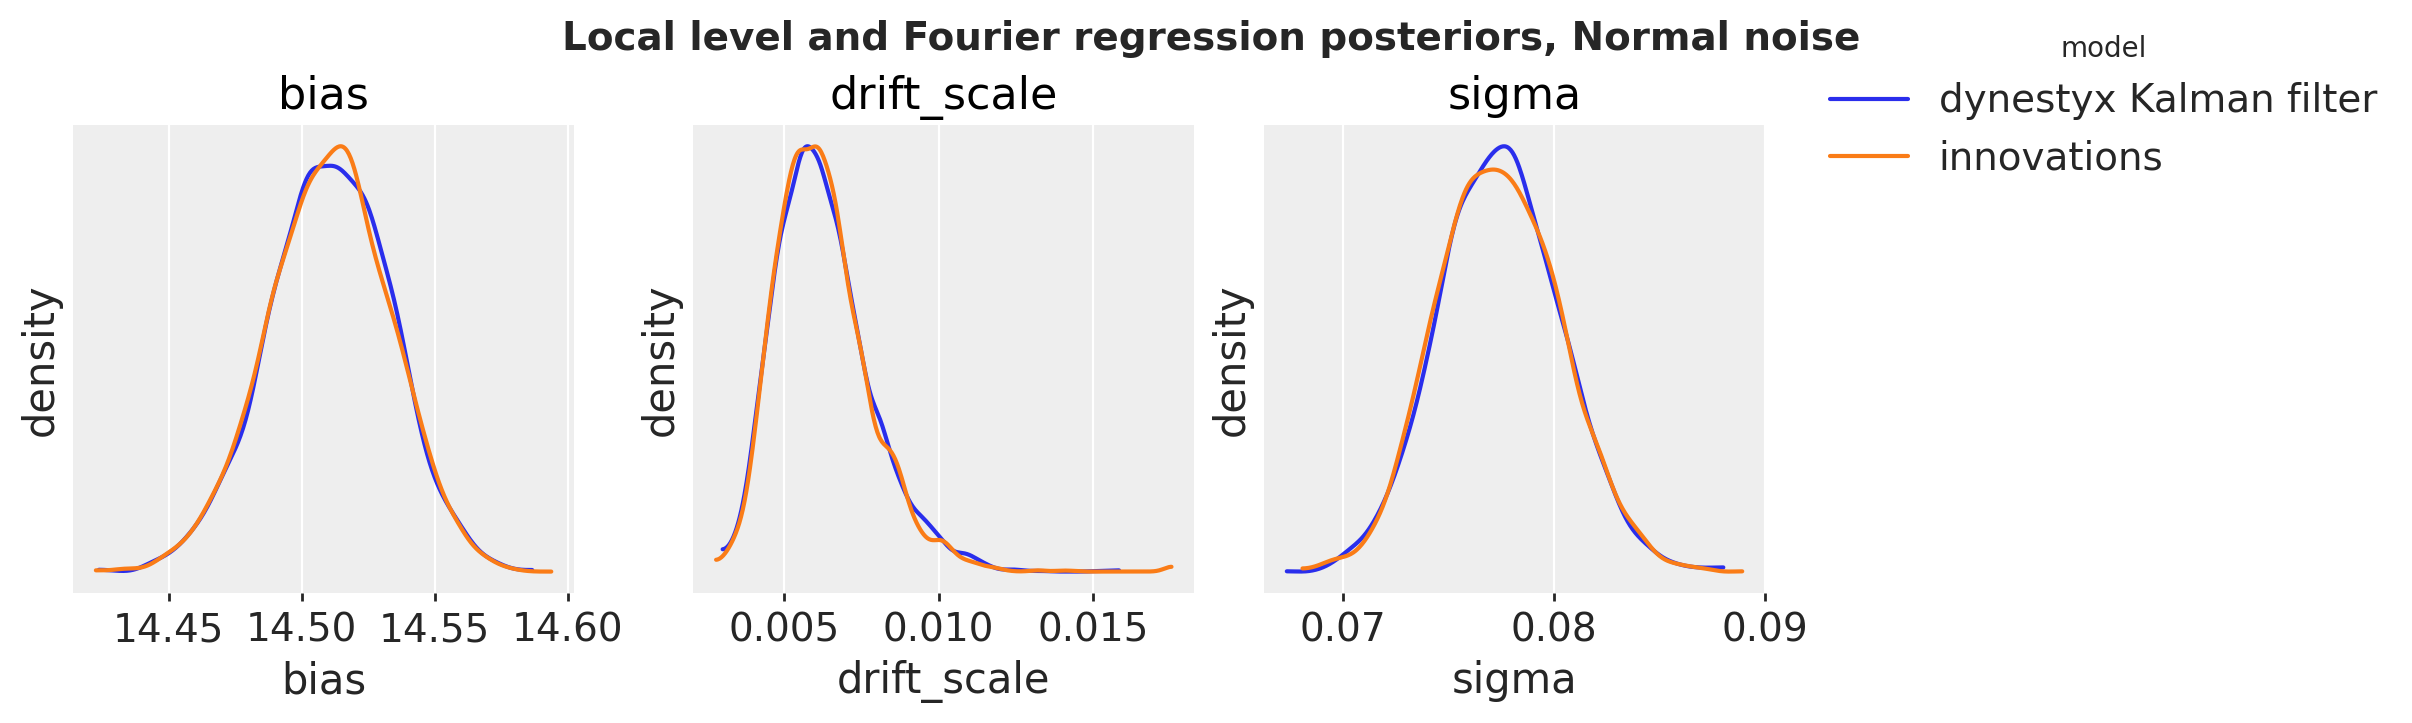

In [9]:
def plot_posteriors(
    fits: dict[str, MCMC], names: list[str], title: str, truth: dict[str, float] | None = None
) -> None:
    """Overlay the posterior densities of ``names`` for every fit, one panel per parameter."""
    trees = {label: posterior_tree(mcmc, names) for label, mcmc in fits.items()}
    with warnings.catch_warnings():
        # fits with different numbers of draws: arviz-plots pads the shorter one with NaN
        # (which the KDE drops), and xarray warns about the padding join
        warnings.filterwarnings("ignore", message="In a future version of xarray")
        pc = az.plot_dist(
            trees,
            var_names=names,
            kind="kde",
            visuals={
                "credible_interval": False,
                "point_estimate": False,
                "point_estimate_text": False,
            },
            figure_kwargs={"figsize": (12, 3.5)},
        )
    pc.add_legend("model")
    for name in names:
        ax = pc.get_target(name, {})
        ax.set(xlabel=name, ylabel="density")
        if truth is not None:
            ax.axvline(truth[name], color="black", ls="--", lw=1)
    pc.viz["figure"].item().suptitle(title, fontsize=14, fontweight="bold")


plot_posteriors(
    {"dynestyx Kalman filter": mcmc_kalman, "innovations": mcmc_innovations},
    ["bias", "drift_scale", "sigma"],
    title="Local level and Fourier regression posteriors, Normal noise",
)

The posteriors of the intercept, of the scale of the weekly steps and of the noise scale coincide.

## In-Sample Predictive and Forecast

`to_datatree` draws the in-sample predictive by calling the model without data, and the forecast by calling it with the full-horizon covariates. For the in-sample predictive the block needs the distribution of the states given the whole window, $p(x_t \mid y_{1:T}, \theta)$. A `Filter` does not have it: it carries the filtering distribution $p(x_t \mid y_{1:t}, \theta)$ only. A Kalman smoother has the smoothing distribution, and it adds the same marginal likelihood to the trace as the Kalman filter. The draws of the filter fit are therefore draws of the posterior under the smoother too, so we export them under the smoother, with the `Simulator` outside it for the forecast, and do not refit.

The block draws every in-sample state from its smoothing distribution and pushes it through the observation model. These draws are exact for every week, so the bands and the CRPS below are correct. They are independent across weeks, while `innovations` replays a joint posterior path.

In [10]:
smoother = Smoother(smoother_config=KFSmootherConfig(filter_source="cd_dynamax"))
# the parameters only: the filter fit also recorded its filtered states (f_filtered_states_*),
# which the export under the smoother does not need
kalman_parameters = {
    name: value for name, value in mcmc_kalman.get_samples().items() if not name.startswith("f_")
}
rng_key, key_tree_kalman, key_tree = random.split(rng_key, 3)

with DiscreteTimeSimulator(n_simulations=1), smoother:
    trees = {
        "dynestyx Kalman smoother": to_datatree(
            key_tree_kalman,
            gaussian_ssm,
            kalman_parameters,
            bart_train,
            bart_covariates,
            num_chains=4,
            batch_size=500,
        )
    }

trees["innovations"] = to_datatree(
    key_tree,
    gaussian_model,
    mcmc_innovations.get_samples(),
    bart_train,
    bart_covariates,
    num_chains=4,
    batch_size=500,
)

trees["dynestyx Kalman smoother"]

<xarray.DataTree>
Group: /
│   Attributes:
│       inference_library:  numpyro
│       creation_library:   numpyro_forecast
│       sample_dims:        ['chain', 'draw']
├── Group: /posterior
│       Dimensions:       (chain: 4, draw: 1000, weight_dim_0: 52)
│       Coordinates:
│         * chain         (chain) int64 32B 0 1 2 3
│         * draw          (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
│         * weight_dim_0  (weight_dim_0) int64 416B 0 1 2 3 4 5 6 ... 46 47 48 49 50 51
│       Data variables:
│           bias          (chain, draw) float32 16kB 14.51 14.5 14.5 ... 14.52 14.52
│           drift_scale   (chain, draw) float32 16kB 0.004764 0.008118 ... 0.008298
│           sigma         (chain, draw) float32 16kB 0.07794 0.07916 ... 0.07391 0.07532
│           weight        (chain, draw, weight_dim_0) float32 832kB -0.01708 ... -0.0102
│       Attributes:
│           created_at:                 2026-11-06T09:49:05.462838+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /posterior_predictive
│       Dimensions:  (chain: 4, draw: 1000, time: 417, obs_dim: 1)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * time     (time) int64 3kB 0 1 2 3 4 5 6 7 ... 410 411 412 413 414 415 416
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (chain, draw, time, obs_dim) float32 7MB 14.36 14.41 ... 13.96
│       Attributes:
│           created_at:                 2026-11-06T09:49:08.284511+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /observed_data
│       Dimensions:  (time: 417, obs_dim: 1)
│       Coordinates:
│         * time     (time) int64 3kB 0 1 2 3 4 5 6 7 ... 410 411 412 413 414 415 416
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (time, obs_dim) float32 2kB 14.41 14.45 14.42 ... 14.71 14.65 14.04
│       Attributes:
│           created_at:                 2026-11-06T09:49:08.284769+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                []
├── Group: /constant_data
│       Dimensions:        (time: 417, covariate_dim: 53)
│       Coordinates:
│         * time           (time) int64 3kB 0 1 2 3 4 5 6 ... 411 412 413 414 415 416
│         * covariate_dim  (covariate_dim) int64 424B 0 1 2 3 4 5 ... 47 48 49 50 51 52
│       Data variables:
│           covariates     (time, covariate_dim) float32 88kB 14.41 0.0 ... -0.2375
│       Attributes:
│           created_at:                 2026-11-06T09:49:08.284956+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                []
├── Group: /predictions
│       Dimensions:  (chain: 4, draw: 1000, time: 52, obs_dim: 1)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * time     (time) int64 416B 417 418 419 420 421 422 ... 464 465 466 467 468
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (chain, draw, time, obs_dim) float32 832kB 14.41 14.6 ... 14.29
│       Attributes:
│           created_at:                 2026-11-06T09:49:09.363806+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
└── Grou

Both trees carry the `posterior_predictive` group (the in-sample draws) and the `predictions` group (the forecast). To score them we merge the `(chain, draw)` dimensions into one sample axis. `plot_crps` then draws the CRPS of each model as a bar, with its value on top.

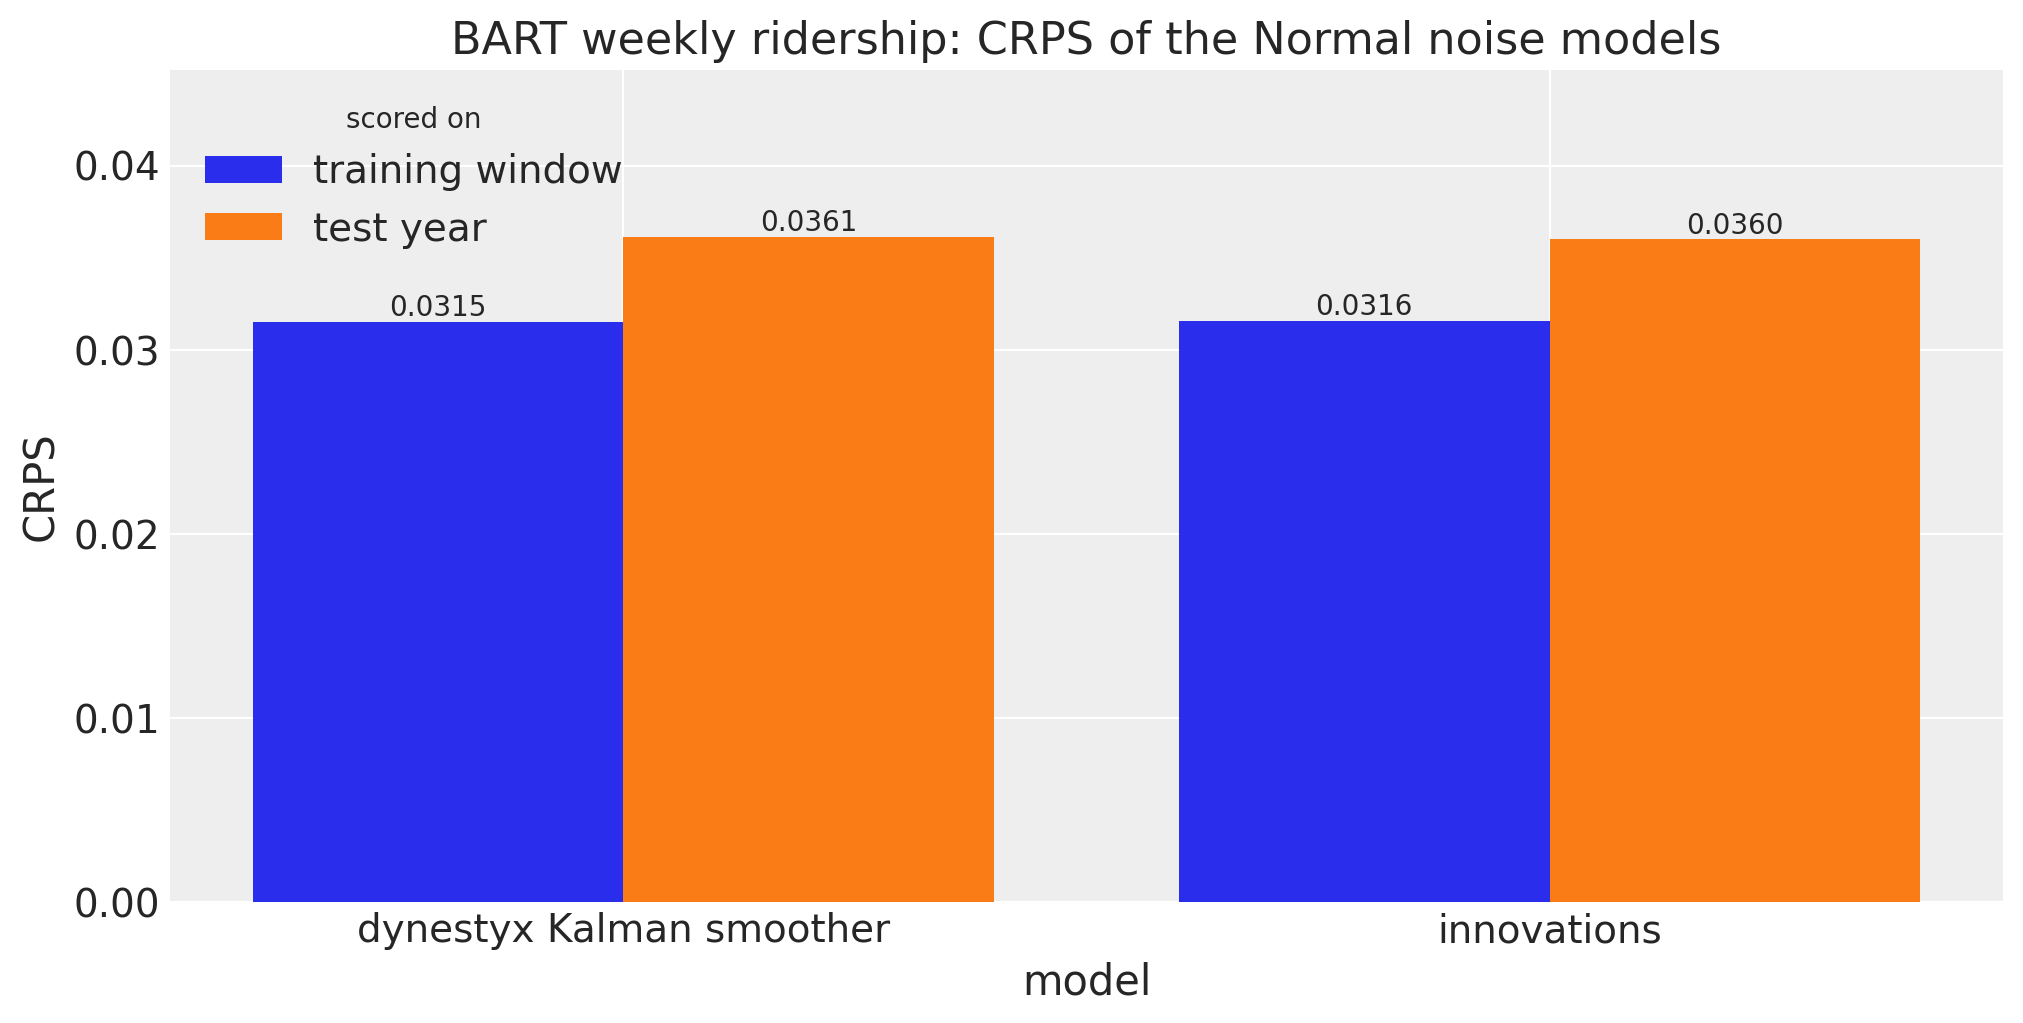

In [11]:
def stacked(tree: xr.DataTree, group: str) -> np.ndarray:
    """Draws of ``tree[group]["obs"]`` with ``(chain, draw)`` merged into ``(sample, time, 1)``."""
    return (
        tree[group]
        .dataset["obs"]
        .stack(sample=("chain", "draw"))
        .transpose("sample", "time", "obs_dim")
        .to_numpy()
    )


def plot_crps(scores: dict[str, dict[str, float]], title: str, xlabel: str = "model") -> None:
    """Bars of the CRPS, ``scores[window][model]``: one group per model, one color per window."""
    models = list(next(iter(scores.values())))
    x = np.arange(len(models))
    width = 0.8 / len(scores)
    _, ax = plt.subplots(figsize=(10, 5))
    for i, (window, by_model) in enumerate(scores.items()):
        offset = (i - (len(scores) - 1) / 2) * width
        bars = ax.bar(
            x + offset, [by_model[m] for m in models], width=width, color=f"C{i}", label=window
        )
        ax.bar_label(bars, fmt="%.4f")
    ax.set_xticks(x, models)
    ax.margins(y=0.25)
    if len(scores) > 1:
        ax.legend(title="scored on", loc="upper left")
    ax.set(title=title, xlabel=xlabel, ylabel="CRPS")


gaussian_crps = {
    "training window": {
        label: float(eval_crps(stacked(tree, "posterior_predictive"), bart_train))
        for label, tree in trees.items()
    },
    "test year": {
        label: float(eval_crps(stacked(tree, "predictions"), bart_test))
        for label, tree in trees.items()
    },
}
plot_crps(gaussian_crps, title="BART weekly ridership: CRPS of the Normal noise models");

The two models give the same in-sample CRPS ($0.0315$ and $0.0316$) and the same test CRPS ($0.0361$ and $0.0360$). Next we look at the in-sample predictive and the forecast of the `dynestyx` model over the last two years of the training window and the test year.

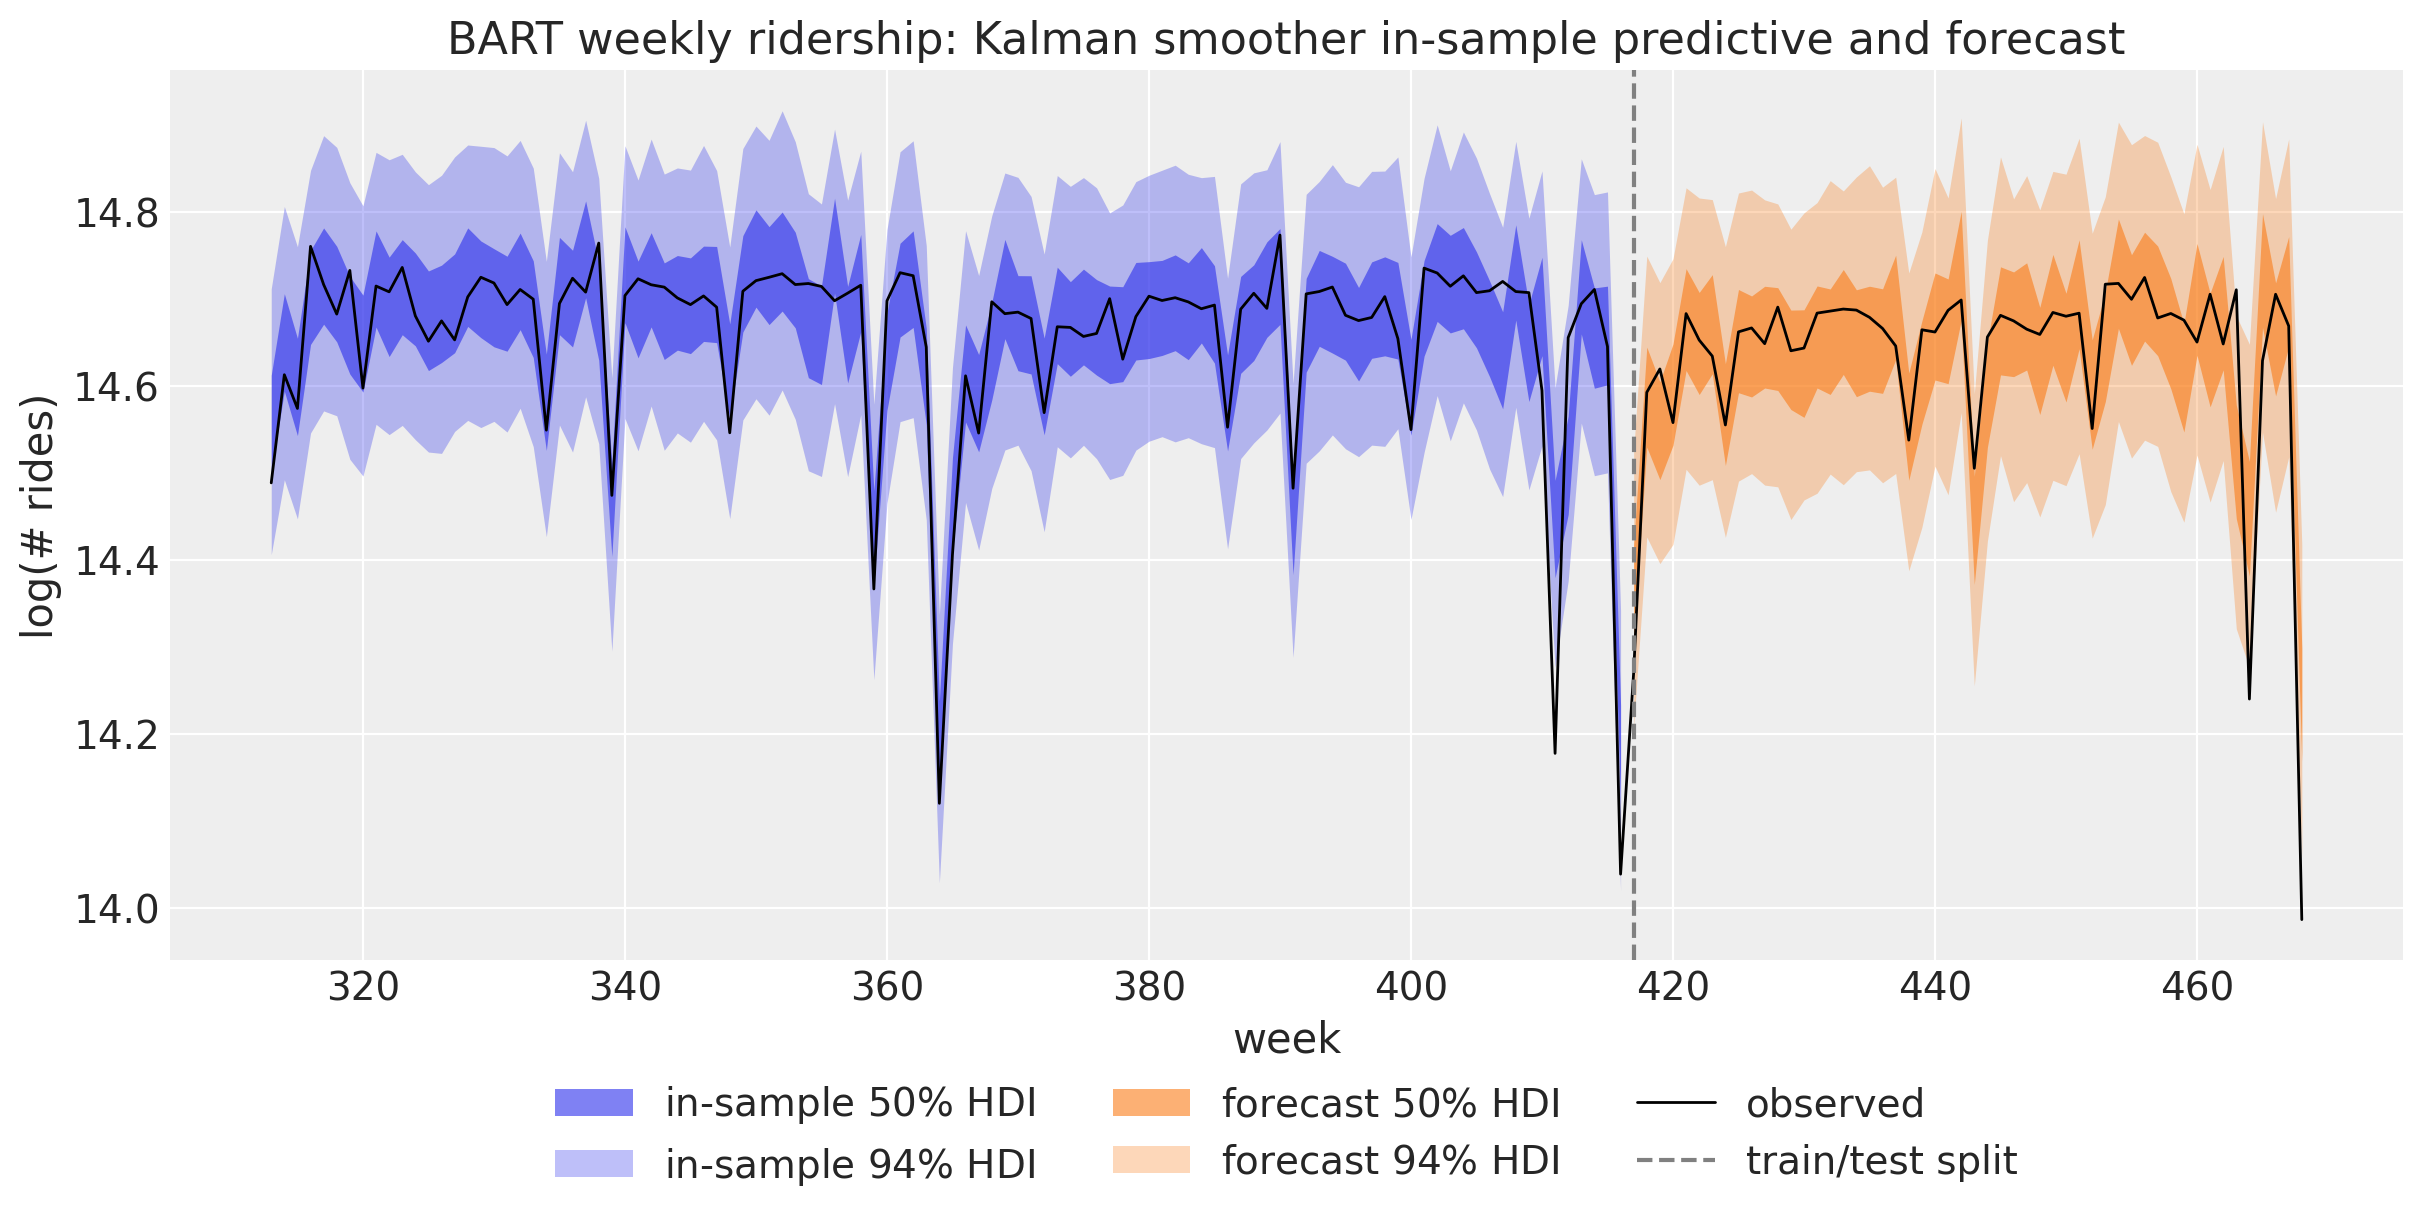

In [12]:
def hdi_label(prob: float, prefix: str = "") -> str:
    r"""Legend label for an HDI band, e.g. ``$94\%$ HDI``."""
    percent = f"{prob:.0%}".replace("%", r"\%")
    return f"{prefix}${percent}$ HDI"


hdi_probs = (0.5, 0.94)
hdi_alphas = [0.6, 0.3]  # 50% band darker, 94% band lighter
start = t_obs - 104  # the last two years of the training window
tree = trees["dynestyx Kalman smoother"]

pc = az.plot_lm(
    predictions_to_datatree(
        stacked(tree, "posterior_predictive")[:, start:], week[start:t_obs], ["bart"]
    ),
    y="obs",
    x="t",
    plot_dim="time",
    ci_kind="hdi",
    ci_prob=hdi_probs,
    smooth=False,
    aes={"alpha": ["prob"]},
    alpha=hdi_alphas,
    visuals={"ci_band": {"color": "C0"}, "observed_scatter": False, "pe_line": False},
    figure_kwargs={"figsize": (12, 6)},
)
in_sample_bands = {prob: pc.viz["ci_band"]["t"].sel(prob=prob).item() for prob in hdi_probs}
az.plot_lm(
    predictions_to_datatree(stacked(tree, "predictions"), week[t_obs:], ["bart"]),
    y="obs",
    x="t",
    plot_dim="time",
    plot_collection=pc,
    ci_kind="hdi",
    ci_prob=hdi_probs,
    smooth=False,
    aes={"alpha": ["prob"]},
    alpha=hdi_alphas,
    visuals={"ci_band": {"color": "C1"}, "observed_scatter": False, "pe_line": False},
)
forecast_bands = {prob: pc.viz["ci_band"]["t"].sel(prob=prob).item() for prob in hdi_probs}
for prob in hdi_probs:
    in_sample_bands[prob].set_label(hdi_label(prob, prefix="in-sample "))
    forecast_bands[prob].set_label(hdi_label(prob, prefix="forecast "))

ax = pc.viz["figure"].item().axes[0]
(obs_line,) = ax.plot(week[start:], bart[start:, 0], color="black", lw=1, label="observed")
split_line = ax.axvline(t_obs, color="gray", ls="--", label="train/test split")
ax.legend(
    handles=[*in_sample_bands.values(), *forecast_bands.values(), obs_line, split_line],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=3,
)
ax.set(
    title="BART weekly ridership: Kalman smoother in-sample predictive and forecast",
    xlabel="week",
    ylabel="log(# rides)",
);

The in-sample band is the observation noise around the smoothed level. The forecast band is about as wide: the weekly steps of the level are small, so one year of them adds little to the observation noise. A few of the sharpest dips, such as the last week of the test year, fall outside the $94\%$ bands. The next section replaces the Normal noise with Student-T noise.

## Student-T Noise with an Explicit Path

The comparing inference methods example uses Student-T noise, whose heavy tails allow for the sharp dips of the series:

$$
y_t = b + \ell_t + \beta^\top u_t + v_t, \qquad v_t \sim \text{StudentT}(\nu, 0, \sigma).
$$

Student-T noise rules out an exact Kalman filter. A particle filter does not combine well with NUTS here: with resampling, the likelihood estimate is not continuous in the parameters, and without it the weights collapse over $417$ weeks. The `dynestyx` model therefore samples the level with a `LatentPathBuilder`, as `innovations` does. The observation model is a function of the state $x_t$, the controls $u_t$ and the time $t$.

The builder samples the states $x_t = b + \ell_t$ directly (the centered form) rather than their steps. With the intercept $b$ as a separate parameter, a change of $b$ must move all $417$ states the other way. In this form the intercept is the initial state, so the `dynestyx` model has no `bias` site and gives the initial state the $\text{Normal}(0, 10)$ prior of the intercept. The two models differ only in the variance $s^2$ that the first step adds to this prior, which is negligible.

In [13]:
def level_regression(covariates: Array, data: Array | None = None) -> None:
    """Random walk level plus Fourier regression with Student-T noise, as a dynestyx model."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :1]
    controls = covariates[..., 1:]
    weight = numpyro.sample(
        "weight", dist.Normal(0.0, 0.1).expand([controls.shape[-1]]).to_event(1)
    )
    drift_scale = numpyro.sample("drift_scale", dist.LogNormal(-20.0, 5.0))
    nu = numpyro.sample("nu", dist.Gamma(10.0, 2.0))
    sigma = numpyro.sample("sigma", dist.LogNormal(-5.0, 5.0))

    def observation(x: Array, u: Array | None, t: Array) -> dist.Distribution:
        regression = 0.0 if u is None else u @ weight
        return dist.StudentT(nu, x + regression, sigma).to_event(1)

    dynamics = DynamicalModel(
        initial_condition=dist.Normal(0.0, 10.0).expand([1]).to_event(1),  # the intercept
        state_evolution=lambda x, u, t_now, t_next: dist.Normal(x, drift_scale).to_event(1),
        observation_model=observation,
        control_dim=controls.shape[-1],
    )
    state_space(h, "f", y, dynamics, controls=controls)

We render the `dynestyx` model after its fit, because the `LatentPathBuilder` needs the concrete data of the fit (see below). As a reference, we write the same model with `innovations` and Student-T noise in `predict`:

In [14]:
def univariate_model(covariates: Array, data: Array | None = None) -> None:
    """Random walk level plus Fourier regression with Student-T noise, with ``innovations``."""
    h = Horizon.from_data(covariates, data)
    fourier = covariates[..., 1:]
    bias = numpyro.sample("bias", dist.Normal(0.0, 10.0))
    weight = numpyro.sample(
        "weight", dist.Normal(0.0, 0.1).expand([fourier.shape[-1]]).to_event(1)
    )
    drift_scale = numpyro.sample("drift_scale", dist.LogNormal(-20.0, 5.0))
    nu = numpyro.sample("nu", dist.Gamma(10.0, 2.0))
    sigma = numpyro.sample("sigma", dist.LogNormal(-5.0, 5.0))
    drift = innovations(
        h, "drift", dist.Normal(0.0, drift_scale), reparam=LocScaleReparam(centered=0)
    )
    level = jnp.cumsum(drift, axis=-2)
    regression = (weight * fourier).sum(axis=-1, keepdims=True)
    predict(h, dist.StudentT(df=nu, loc=0.0, scale=sigma), level + bias + regression)

Next, we render the `innovations` model:

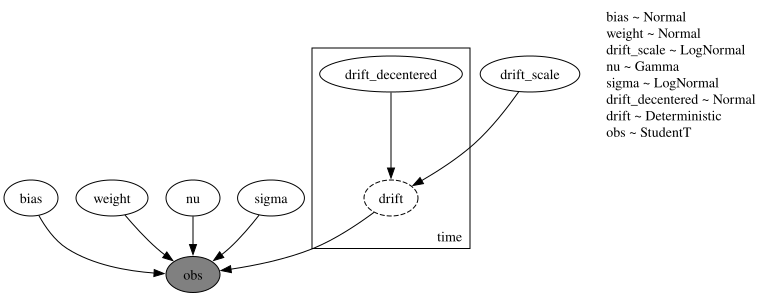

In [15]:
numpyro.render_model(
    univariate_model,
    model_args=(bart_covariates[:t_obs], bart_train),
    render_distributions=True,
)

Compared with the Normal model, the graph has one more parameter: the degrees of freedom `nu` of the Student-T noise.

Both fits run their chains one after the other (`chain_method="sequential"`). Parallel chains under a `LatentPathBuilder` crashed the Python process with `dynestyx` $0.8.0$ and Python $3.14$ on the machine that executed this notebook (`dynestyx` declares support for Python $3.12$ and $3.13$). The explicit path runs $4{,}000$ warmup steps and $4{,}000$ draws per chain, against $2{,}000$ and $1{,}000$ for `innovations`, because it mixes more slowly. The per-parameter table below shows its slowest parameter.

We keep the `LatentPathBuilder` instance of the fit. The builder records the pattern of missing observations from the concrete data of the fit. The drivers later run the model under `jax.jit`, where the data are traced, so every later call must use the same instance.

In [16]:
latent_path = LatentPathBuilder()
rng_key, key_latent, key_univariate = random.split(rng_key, 3)

with latent_path:
    mcmc_latent, seconds = fit_nuts(
        key_latent,
        level_regression,
        bart_covariates[:t_obs],
        bart_train,
        num_warmup=4_000,
        num_samples=4_000,
        chain_method="sequential",
    )

student_fits = {"dynestyx latent path": diagnostics(mcmc_latent, seconds)}

mcmc_univariate, seconds = fit_nuts(
    key_univariate,
    univariate_model,
    bart_covariates[:t_obs],
    bart_train,
    num_warmup=2_000,
    chain_method="sequential",
)
student_fits["innovations"] = diagnostics(mcmc_univariate, seconds)

fits_table(student_fits)

fit,parameters,min bulk ESS,max R-hat,divergences,leapfrog steps per draw,wall time (s)
str,i64,i64,f64,i64,f64,f64
"""dynestyx latent path""",472,439,1.005,0,135.2,54.8
"""innovations""",473,946,1.006,0,255.0,73.5


With these chain lengths both fits converge over all their parameters:

- The largest $\hat{R}$ is $1.006$ and the smallest bulk ESS is $439$. There are no divergent transitions.
- The two fits ran chains of different lengths, so their wall times do not compare their cost.
- Per draw, the explicit path takes $135.2$ leapfrog steps and `innovations` $255.0$, the length of a NUTS tree of depth $8$.

Now we can render the `dynestyx` model. `numpyro.render_model` traces the model, as the drivers do, so it needs the builder of the fit, which has recorded the pattern of missing observations:

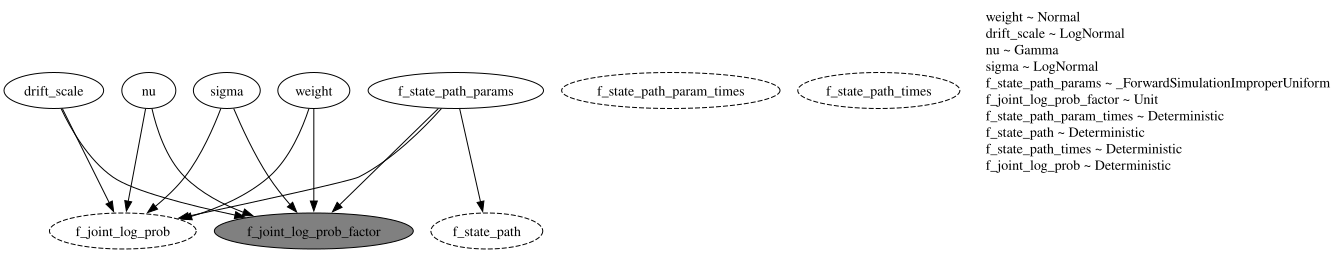

In [17]:
with latent_path:
    graph = numpyro.render_model(
        level_regression,
        model_args=(bart_covariates[:t_obs], bart_train),
        render_distributions=True,
    )

graph

The builder adds the latent path as one sample site, `f_state_path_params`, which holds the $417$ weekly states. The parameters and the path feed the gray factor `f_joint_log_prob_factor`: the joint log density of the path and the observations. The dashed nodes are deterministic sites that `dynestyx` records, such as the path `f_state_path`.

Next, we look at the diagnostics of the three scalar parameters that both models share:

In [18]:
student_names = ["drift_scale", "nu", "sigma"]  # both models also share the 52 weights
student_summaries = {
    label: az.summary(posterior_tree(mcmc, student_names), fmt="xarray", round_to="none")
    for label, mcmc in (("dynestyx latent path", mcmc_latent), ("innovations", mcmc_univariate))
}
pl.DataFrame(
    [
        {"fit": label, "parameter": name}
        | {
            stat: float(summary[name].sel(summary=stat))
            for stat in ("mean", "sd", "ess_bulk", "r_hat")
        }
        for label, summary in student_summaries.items()
        for name in student_names
    ]
).with_columns(
    pl.col("mean", "sd").round(4),
    pl.col("ess_bulk").round(0).cast(pl.Int64),
    pl.col("r_hat").round(3),
)

fit,parameter,mean,sd,ess_bulk,r_hat
str,str,f64,f64,i64,f64
"""dynestyx latent path""","""drift_scale""",0.0044,0.0008,439,1.005
"""dynestyx latent path""","""nu""",1.5749,0.2216,9972,1.0
"""dynestyx latent path""","""sigma""",0.0172,0.002,6682,1.001
"""innovations""","""drift_scale""",0.0045,0.0007,1335,1.004
"""innovations""","""nu""",1.5674,0.2233,1228,1.001
"""innovations""","""sigma""",0.0171,0.002,946,1.001


`drift_scale` is the slowest parameter of the explicit path: its bulk ESS is $439$ from $16{,}000$ draws, against $1{,}335$ from $4{,}000$ draws for `innovations`. The builder samples the states in centered form and has no reparameterization option, while `innovations` samples the non-centered steps.

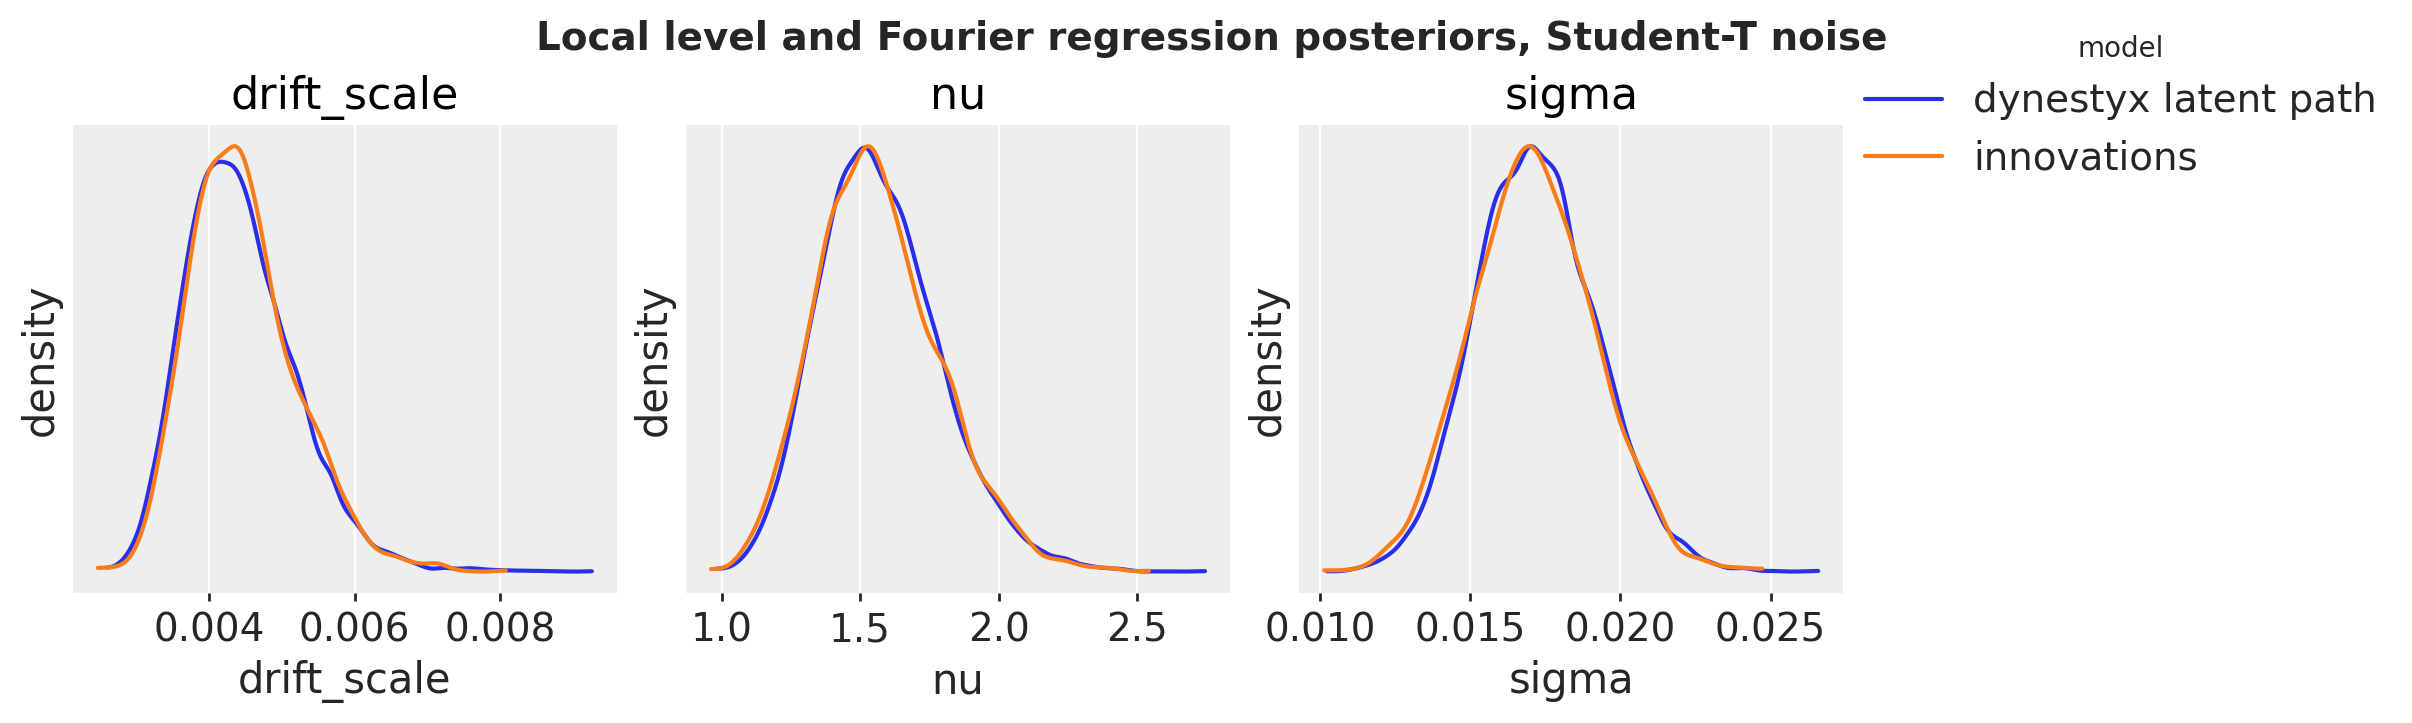

In [19]:
plot_posteriors(
    {"dynestyx latent path": mcmc_latent, "innovations": mcmc_univariate},
    student_names,
    title="Local level and Fourier regression posteriors, Student-T noise",
)

The posteriors of the three shared parameters coincide.

Both models forecast through `forecast`. The `LatentPathBuilder` around the call is the instance that fitted the model.

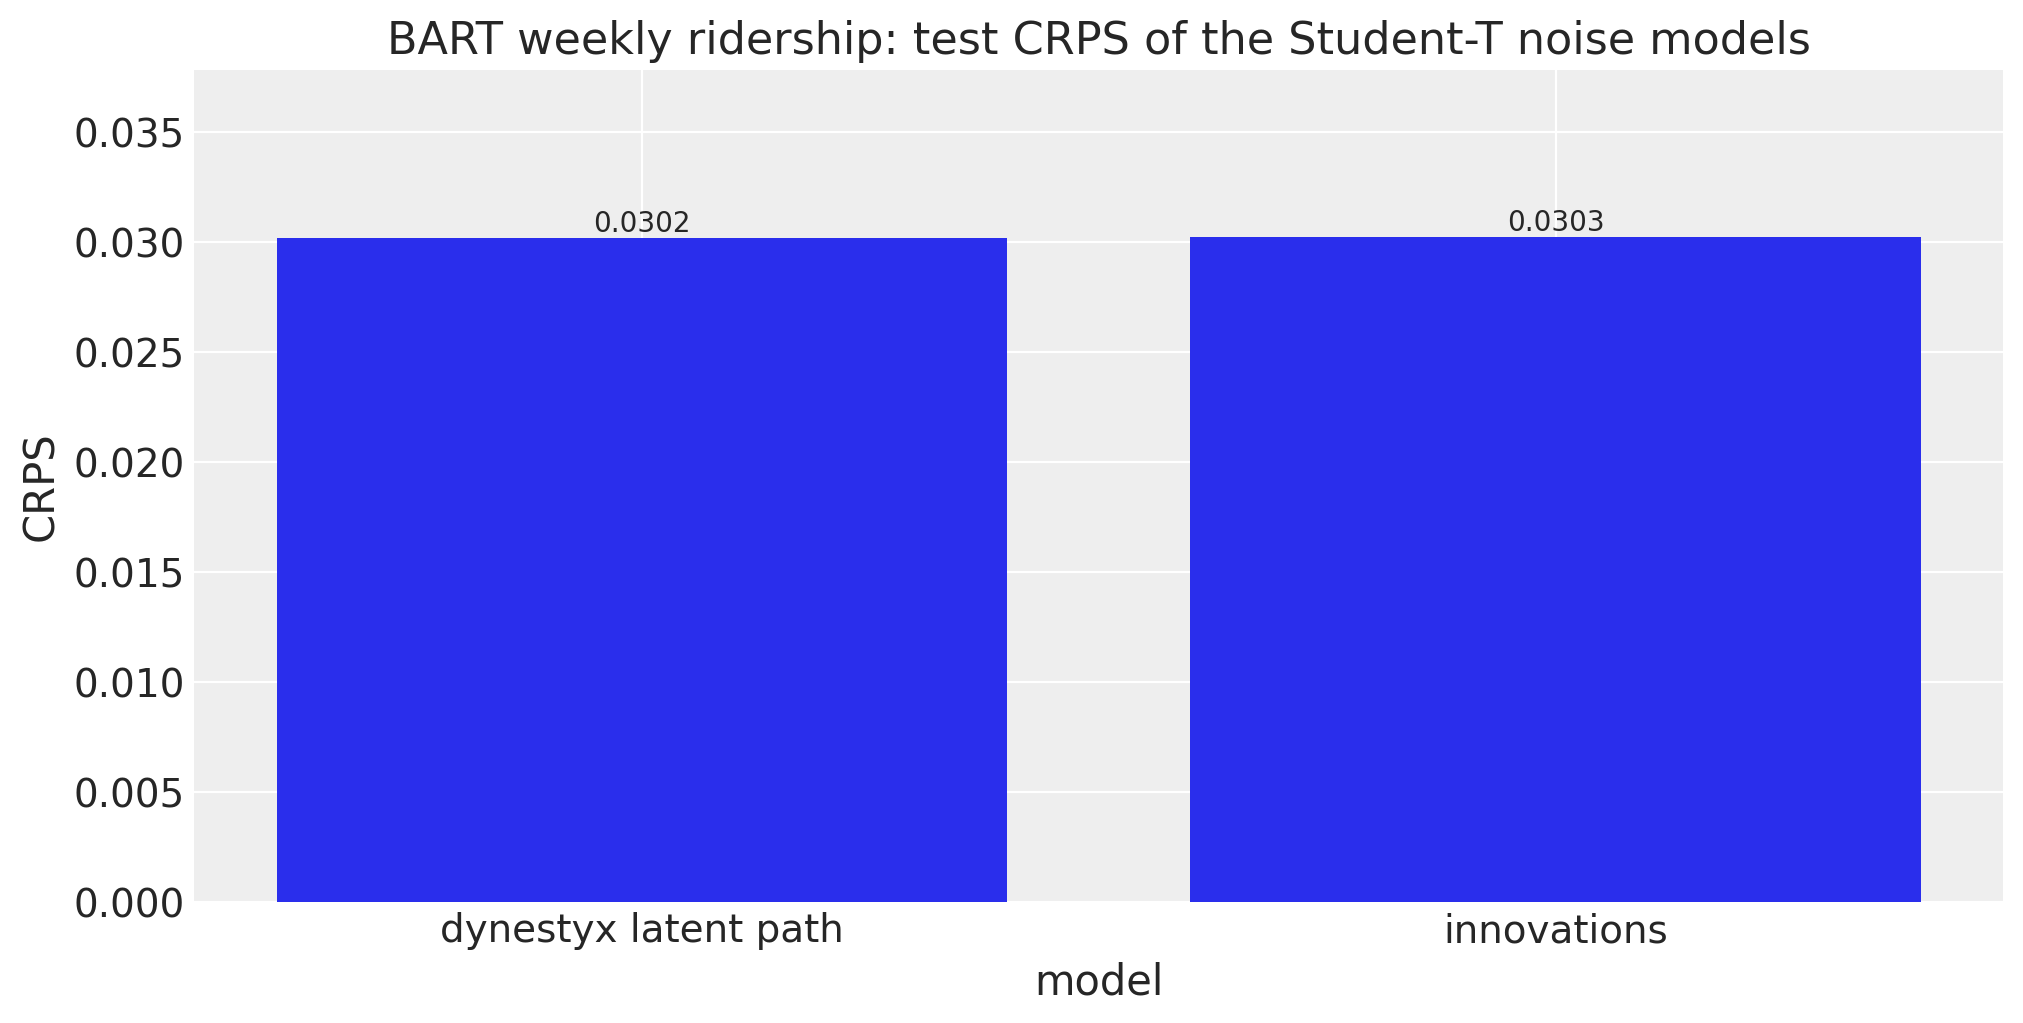

In [20]:
rng_key, key_latent, key_univariate = random.split(rng_key, 3)

with DiscreteTimeSimulator(n_simulations=1), latent_path:
    student_forecasts = {
        "dynestyx latent path": forecast(
            key_latent,
            level_regression,
            mcmc_latent.get_samples(),
            bart_train,
            bart_covariates,
            batch_size=500,
        )
    }

student_forecasts["innovations"] = forecast(
    key_univariate,
    univariate_model,
    mcmc_univariate.get_samples(),
    bart_train,
    bart_covariates,
    batch_size=500,
)

student_crps = {
    label: float(eval_crps(draws, bart_test)) for label, draws in student_forecasts.items()
}
plot_crps(
    {"test year": student_crps},
    title="BART weekly ridership: test CRPS of the Student-T noise models",
);

The test CRPS is $0.0302$ for the explicit path and $0.0303$ for `innovations`. Both score better than the Normal models of the previous section (test CRPS $0.0361$ and $0.0360$). We plot the two forecasts one above the other. The point estimate is the median of the draws: with $\nu$ near $1.6$ the Student-T noise has no finite variance, so a few extreme draws move the mean. The explicit path has four times as many draws as `innovations`, so we thin them to the same number for the figure.

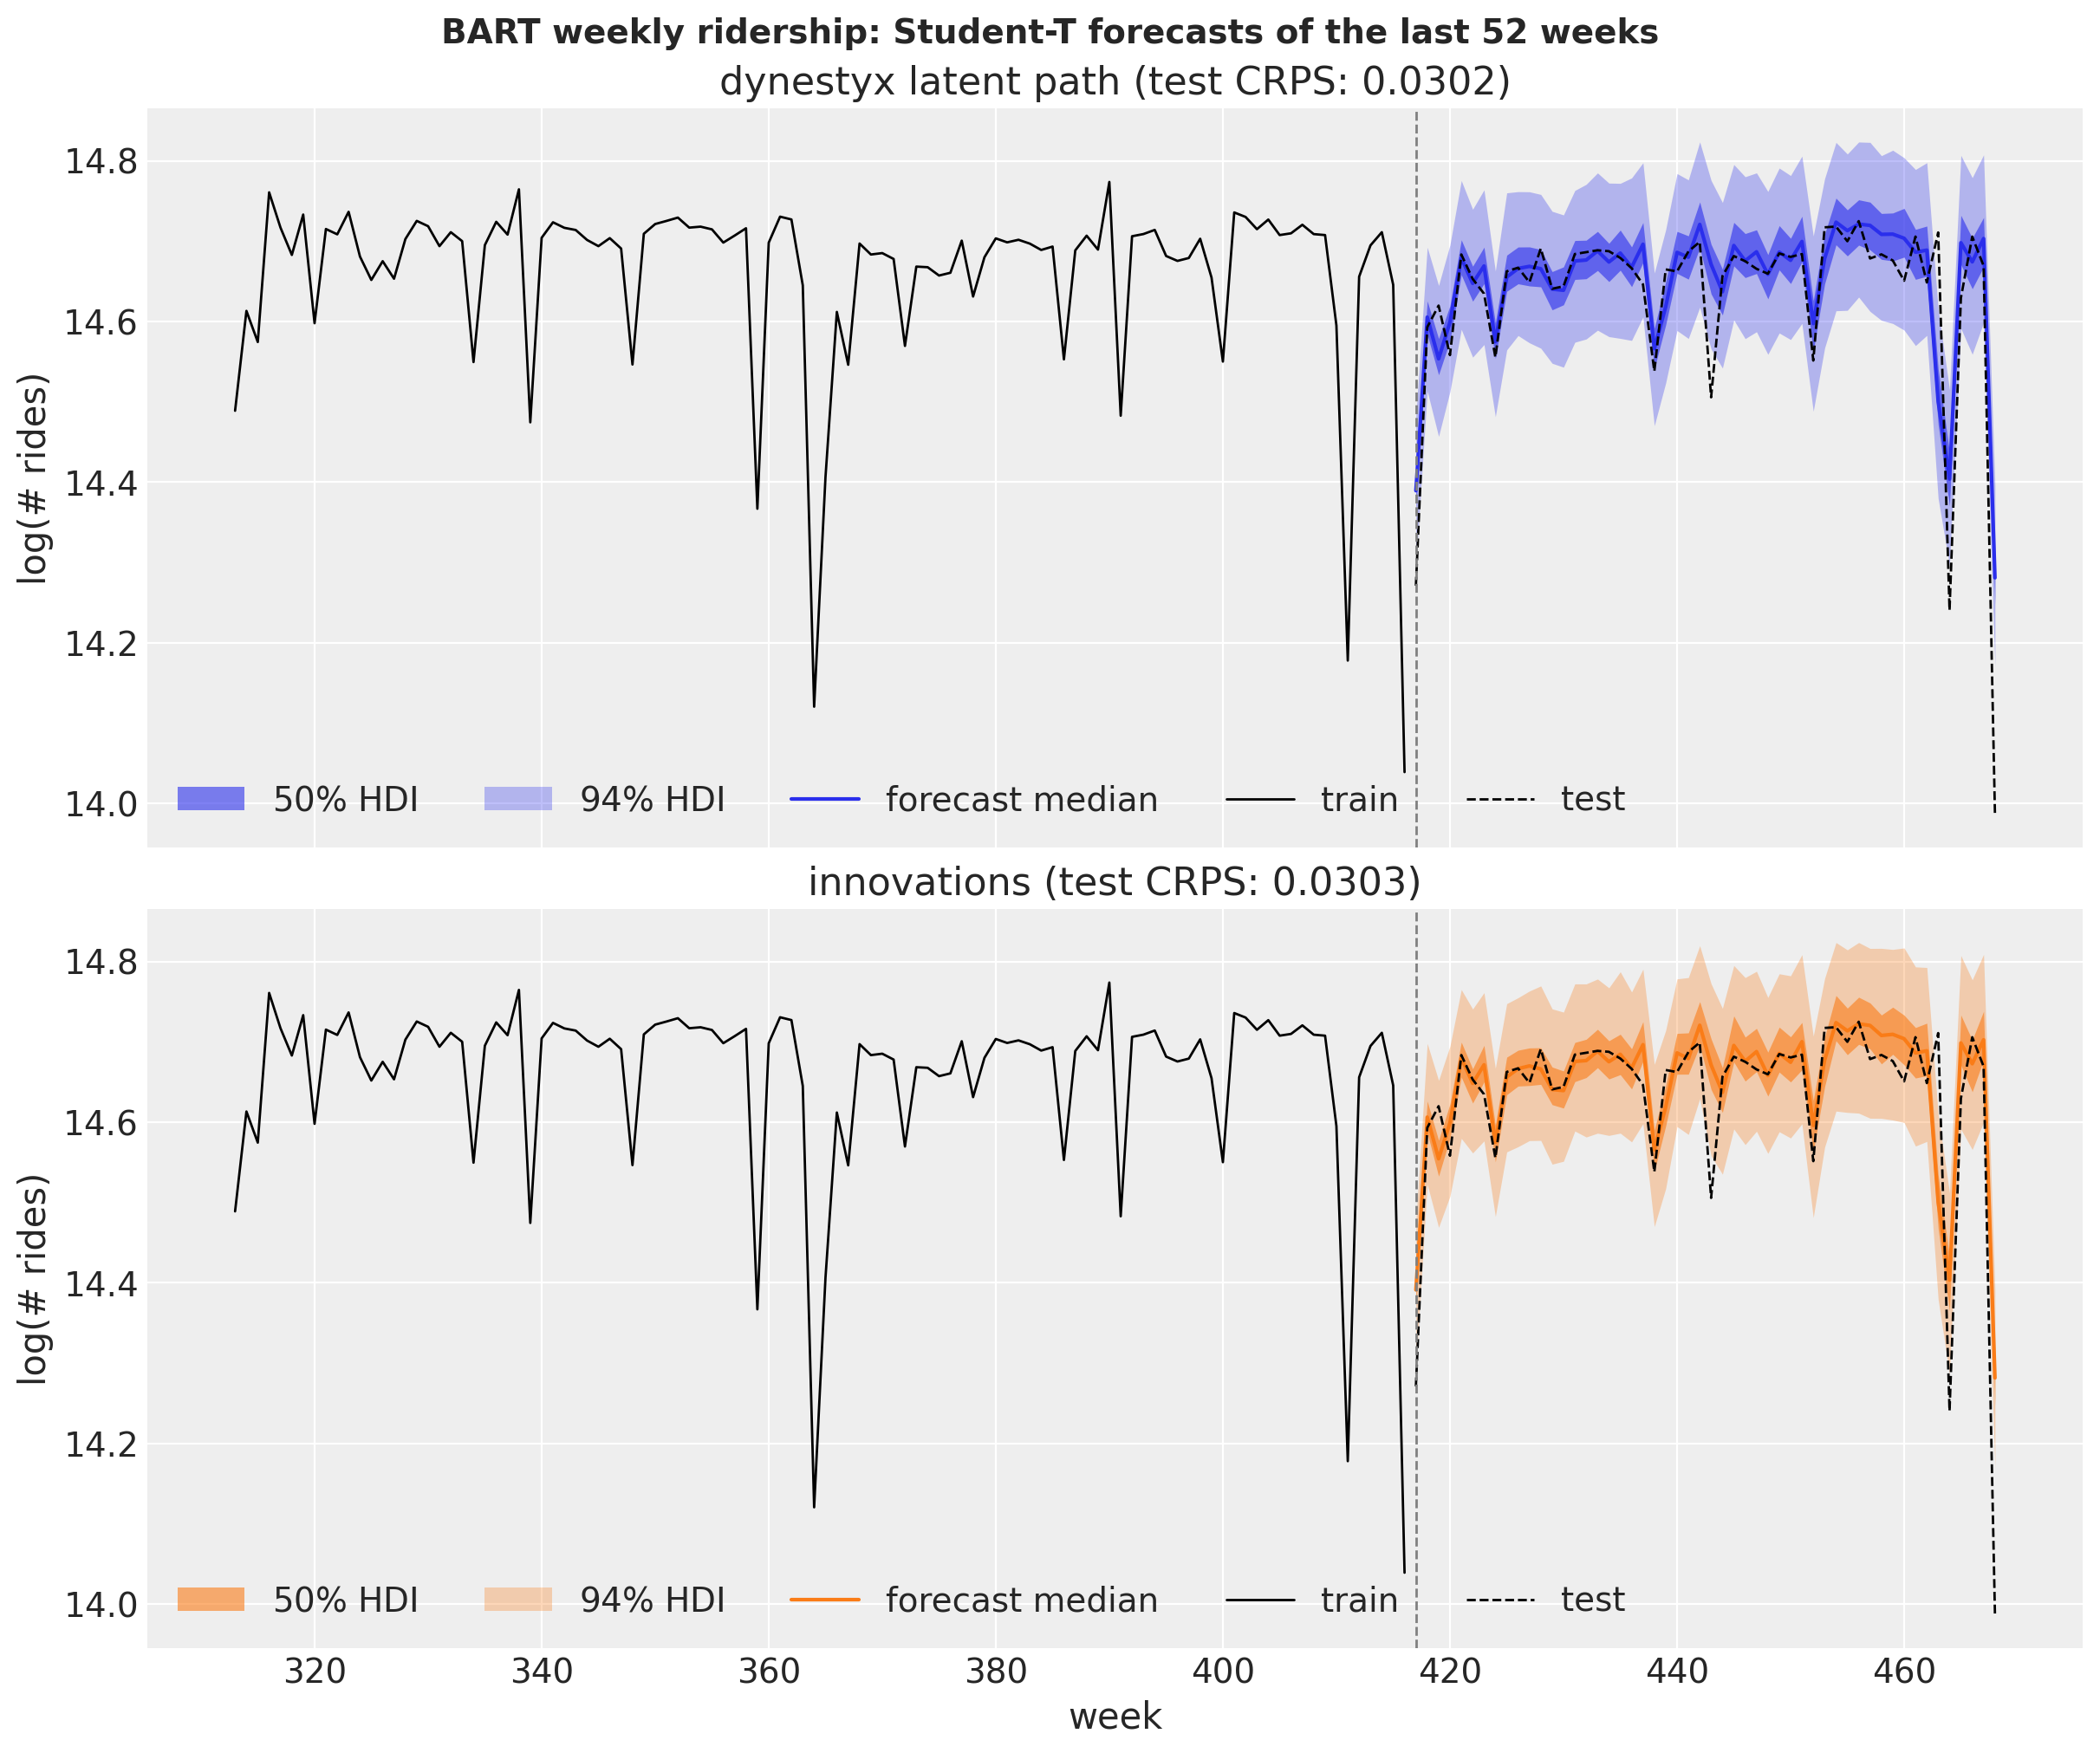

In [21]:
num_draws = min(len(draws) for draws in student_forecasts.values())
thinned = [np.asarray(draws)[:: len(draws) // num_draws] for draws in student_forecasts.values()]
pc = az.plot_lm(
    predictions_to_datatree(
        np.concatenate(thinned, axis=-1),
        week[t_obs:],
        list(student_forecasts),
    ),
    y="obs",
    x="t",
    plot_dim="time",
    ci_kind="hdi",
    ci_prob=hdi_probs,
    smooth=False,
    point_estimate="median",
    col_wrap=1,
    aes={"color": ["series"], "alpha": ["prob"]},
    alpha=hdi_alphas,
    aes_by_visuals={"pe_line": ["color"]},
    visuals={
        "observed_scatter": False,
        "pe_line": {"alpha": 1.0, "width": 1.5},
        "xlabel": False,
        "ylabel": False,
    },
    figure_kwargs={"figsize": (12, 10), "sharex": True, "sharey": True},
)
history = slice(t_obs - 104, t_obs)
for label in student_forecasts:
    ax = pc.get_target("t", {"series": label})
    ax.plot(week[history], bart_train[history, 0], color="black", lw=1, label="train")
    ax.plot(week[t_obs:], bart_test[:, 0], color="black", lw=1, ls="--", label="test")
    ax.axvline(t_obs, color="gray", ls="--", lw=1)
    ax.set(title=f"{label} (test CRPS: {student_crps[label]:.4f})", ylabel="log(# rides)")
    for prob in hdi_probs:
        pc.viz["ci_band"]["t"].sel(series=label, prob=prob).item().set_label(hdi_label(prob))
    pc.viz["pe_line"]["t"].sel(series=label).item().set_label("forecast median")
    ax.legend(loc="lower left", ncol=5)
ax.set(xlabel="week")
pc.viz["figure"].item().suptitle(
    "BART weekly ridership: Student-T forecasts of the last 52 weeks",
    fontsize=14,
    fontweight="bold",
);

The two panels show the same forecast: over the test year the medians and the HDI bands of the two models agree closely.

## Missing Data

The `LatentPathBuilder` skips missing observations, so the Student-T model fits through a gap with no change to the model function. (The Kalman filter and smoother of the `cuthbert` backend skip them too, while the `cd_dynamax` backend rejects them.) We remove $20$ weeks of the training window by setting them to `NaN` in two places. The block reads the observed window from column $0$ of the covariates, so the gap has to go there to reach the likelihood. A `NaN` in `data` alone would not reach it. We also put the gap into `data`, which `to_datatree` would store as the observed data.

The gap fit gets its own `LatentPathBuilder` and the longer chains of the explicit path. A builder keeps one pattern of missing observations per site name and shape. A second fit with the same builder and a different pattern replaces it, and a later call that evaluates the likelihood of the first model (a refit or `log_density`) then fails.

In [22]:
gap = slice(300, 320)
bart_gap = bart_train.at[gap].set(jnp.nan)
bart_covariates_gap = bart_covariates.at[gap, 0].set(jnp.nan)
gap_builder = LatentPathBuilder()
rng_key, key_gap = random.split(rng_key)

with gap_builder:
    mcmc_gap, seconds = fit_nuts(
        key_gap,
        level_regression,
        bart_covariates_gap[:t_obs],
        bart_gap,
        num_warmup=4_000,
        num_samples=4_000,
        chain_method="sequential",
    )

fits_table({"gap fit": diagnostics(mcmc_gap, seconds)})

fit,parameters,min bulk ESS,max R-hat,divergences,leapfrog steps per draw,wall time (s)
str,i64,i64,f64,i64,f64,f64
"""gap fit""",472,355,1.013,0,163.6,55.5


The gap fit nearly converges: the largest $\hat{R}$ is $1.013$, just above the usual threshold of $1.01$, the smallest bulk ESS is $355$, and there are no divergent transitions. The conclusions below are qualitative and unlikely to change with longer chains.

We draw the in-sample predictive of the gap fit, which covers the gap weeks, under the builder of that fit. As a reference we draw the in-sample predictive of the fit on all weeks from the previous section. That fit has seen the weeks of the gap, so we expect it to score better there.

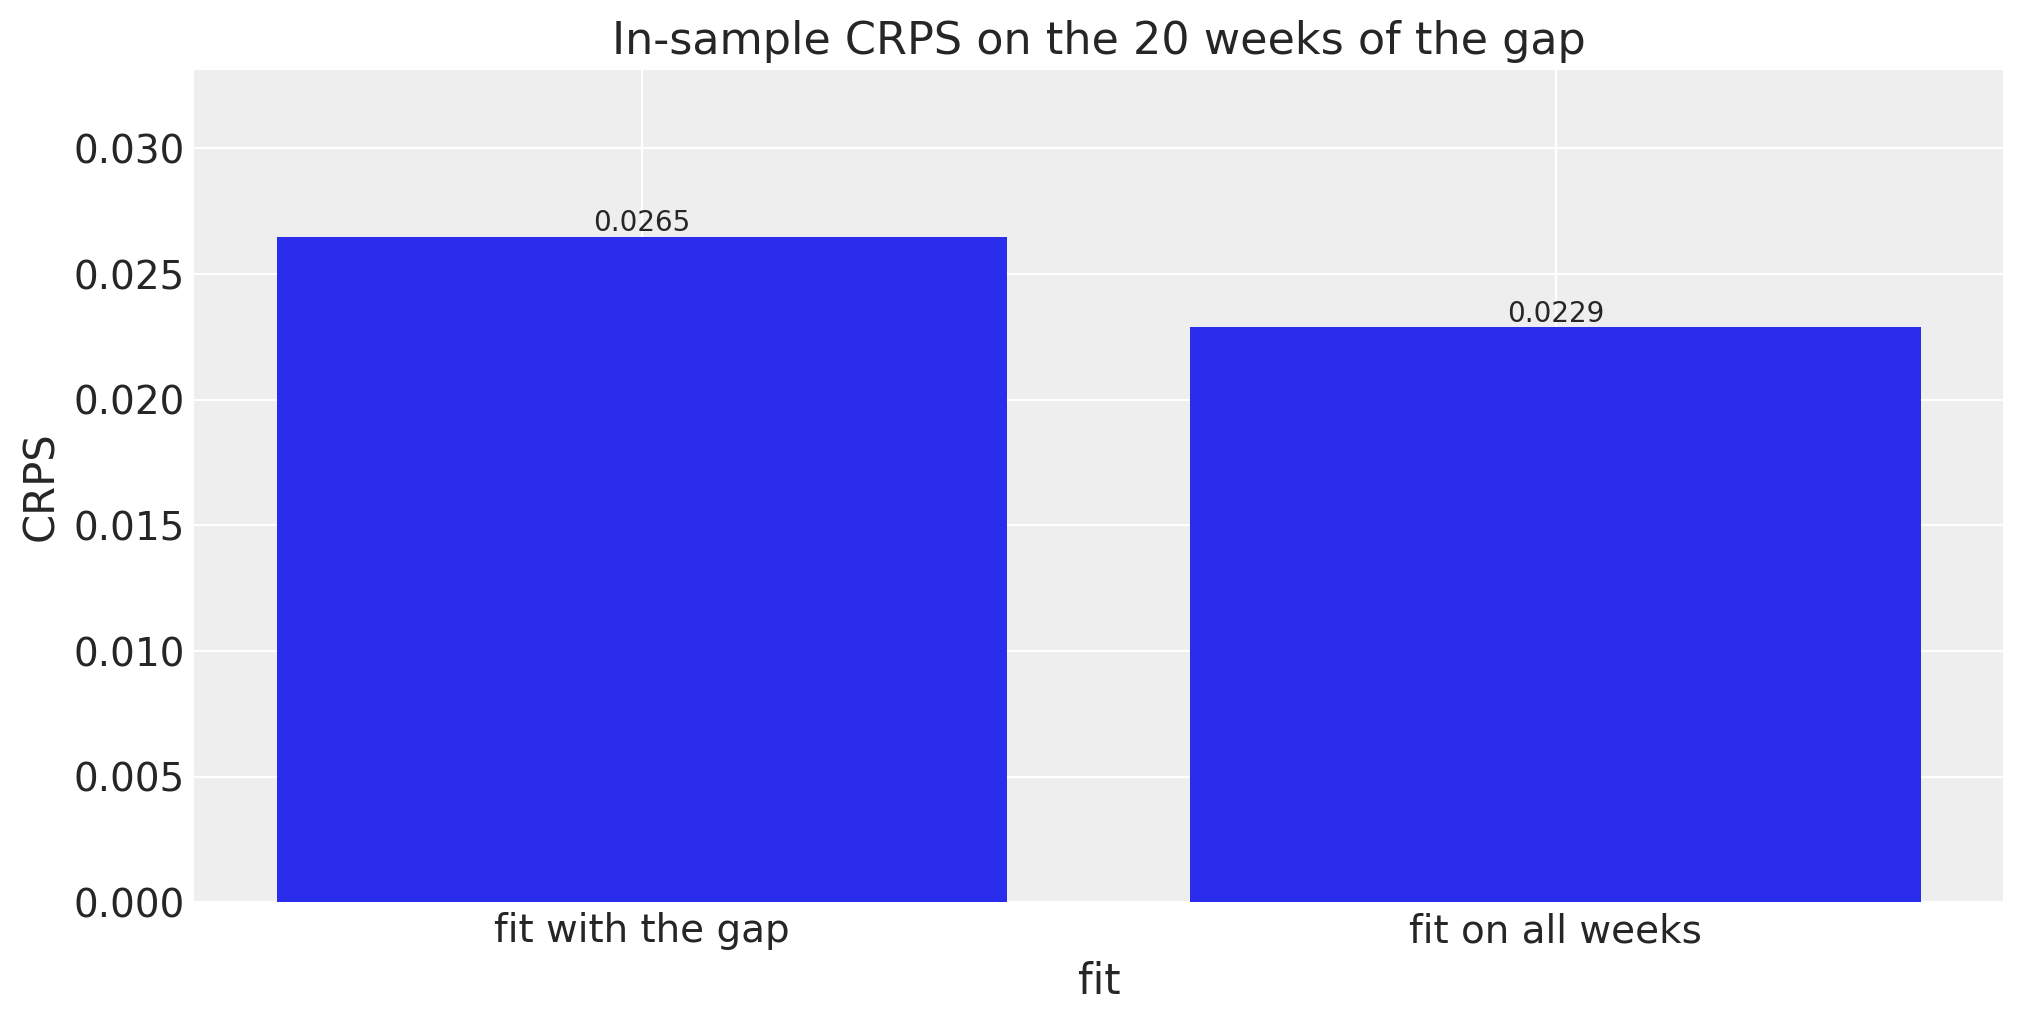

In [23]:
rng_key, key_gap_pred, key_full_pred = random.split(rng_key, 3)
in_sample = {}

with gap_builder:
    in_sample["fit with the gap"] = predict_in_sample(
        key_gap_pred,
        level_regression,
        mcmc_gap.get_samples(),
        bart_covariates_gap[:t_obs],
        batch_size=500,
    )

with latent_path:
    in_sample["fit on all weeks"] = predict_in_sample(
        key_full_pred,
        level_regression,
        mcmc_latent.get_samples(),
        bart_covariates[:t_obs],
        batch_size=500,
    )

gap_crps = {
    label: float(eval_crps(draws[:, gap], bart_train[gap])) for label, draws in in_sample.items()
}
plot_crps(
    {"gap weeks": gap_crps}, title="In-sample CRPS on the 20 weeks of the gap", xlabel="fit"
);

On the $20$ held-out weeks the CRPS of the gap fit is $0.0265$, against $0.0229$ for the fit that saw them. We plot the in-sample predictive of the gap fit around the gap, with the median of the fit on all weeks as a reference.

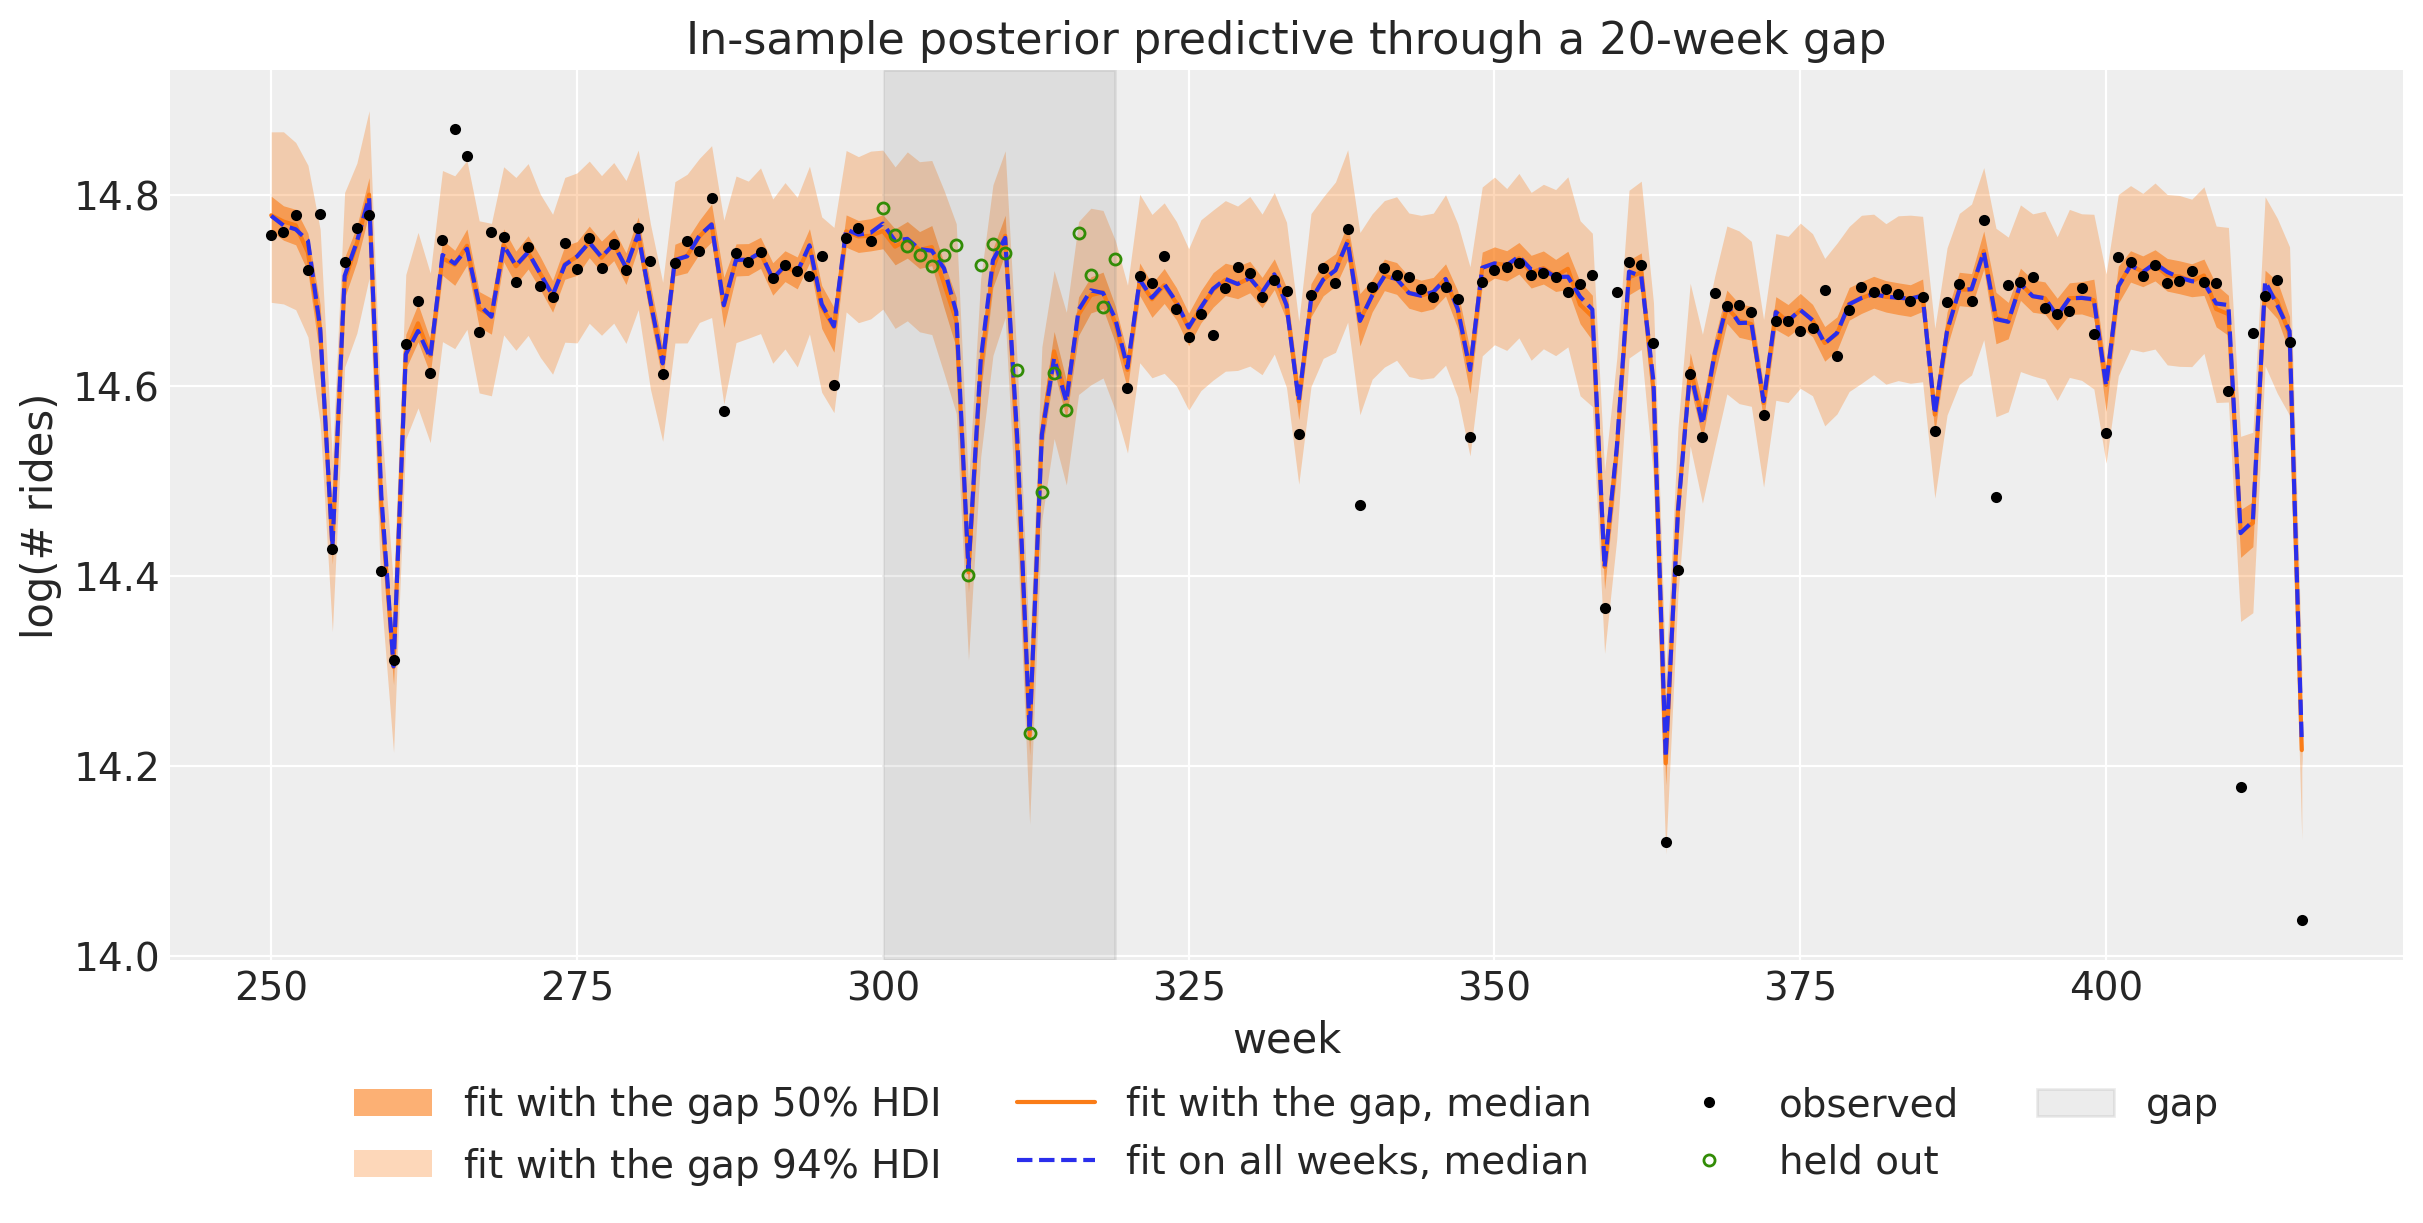

In [24]:
window = slice(250, t_obs)
pc = az.plot_lm(
    predictions_to_datatree(
        np.asarray(in_sample["fit with the gap"])[:, window], week[window], ["bart"]
    ),
    y="obs",
    x="t",
    plot_dim="time",
    ci_kind="hdi",
    ci_prob=hdi_probs,
    smooth=False,
    aes={"alpha": ["prob"]},
    alpha=hdi_alphas,
    point_estimate="median",
    visuals={
        "ci_band": {"color": "C1"},
        "observed_scatter": False,
        "pe_line": {"color": "C1", "alpha": 1.0, "width": 1.5},
    },
    figure_kwargs={"figsize": (12, 6)},
)
for prob in hdi_probs:
    pc.viz["ci_band"]["t"].sel(prob=prob).item().set_label(hdi_label(prob, "fit with the gap "))
pc.viz["pe_line"]["t"].item().set_label("fit with the gap, median")
ax = pc.viz["figure"].item().axes[0]
ax.plot(
    week[window],
    np.median(np.asarray(in_sample["fit on all weeks"]), axis=0)[window, 0],
    color="C0",
    ls="--",
    label="fit on all weeks, median",
)
ax.plot(week[window], bart_gap[window, 0], "o", color="black", ms=3, label="observed")
ax.plot(week[gap], bart_train[gap, 0], "o", color="C2", ms=4, mfc="none", label="held out")
ax.axvspan(gap.start, gap.stop - 1, color="gray", alpha=0.15, label="gap")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
ax.set(
    title="In-sample posterior predictive through a 20-week gap",
    xlabel="week",
    ylabel="log(# rides)",
);

The band of the gap fit follows the Fourier regression through the gap, including the two dips of the yearly cycle inside it. The median of the fit on all weeks stays inside the band.

## A Two-Dimensional State: ARMA(1,1)

The local level has a one-dimensional state. The [ARMA example](arma.html) writes the ARMA(1,1) model

$$
y_t = \mu + \phi \, y_{t-1} + \theta \, \varepsilon_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \text{Normal}(0, \sigma)
$$

with `ssoe`, which conditions on $y_{-1} = \mu$ and $\varepsilon_{-1} = 0$. The same model is a linear-Gaussian state space model with a two-dimensional state, so the Kalman filter gives the exact likelihood instead. With the deviation $a_t = y_t - c$ from the process mean $c = \mu / (1 - \phi)$, the state $x_t = (a_t, \theta \varepsilon_t)$ follows

$$
x_t = A x_{t-1} + g \, \varepsilon_t, \qquad A = \begin{pmatrix} \phi & 1 \\ 0 & 0 \end{pmatrix}, \qquad g = \begin{pmatrix} 1 \\ \theta \end{pmatrix},
$$

so the state covariance is $Q = \sigma^2 g g^\top$, and the observation is $y_t = H x_t + c$ with $H = (1, 0)$. The initial state has the stationary covariance $P_0$, the solution of $P_0 = A P_0 A^\top + Q$. The state noise has rank one, so we add a small jitter $\delta = 10^{-4} \sigma^2$ to $Q$, to $P_0$ and as the observation variance, which keeps the Cholesky factors defined in single precision.

We simulate $100$ steps with $\phi = 0.4$, $\theta = 0.7$ and $\sigma = 0.5$, as the ARMA example does.

In [25]:
phi_true, theta_true, noise_scale, n_steps = 0.4, 0.7, 0.5, 100


def simulate_arma(
    rng_key: Array, n: int, phi: float, theta: float, scale: float
) -> Float[Array, " time"]:
    """Simulate ``n`` steps of a zero-mean ARMA(1,1) process."""
    error = scale * random.normal(rng_key, (n + 1,))

    def step(carry: tuple[Array, Array], noise: Array) -> tuple[tuple[Array, Array], Array]:
        y_prev, error_prev = carry
        y_t = phi * y_prev + theta * error_prev + noise
        return (y_t, noise), y_t

    return jax.lax.scan(step, (jnp.zeros(()), error[0]), error[1:])[1]


rng_key, rng_subkey = random.split(rng_key)
arma_data = simulate_arma(rng_subkey, n_steps, phi_true, theta_true, noise_scale)[:, None]
arma_covariates = arma_data  # both models read the observed series from the covariates

`arma_dynamics` builds the matrices above:

In [26]:
def arma_dynamics(mu: Array, phi: Array, theta: Array, sigma: Array) -> DynamicalModel:
    """ARMA(1,1) as a linear-Gaussian state space model with a stationary initial state."""
    A = jnp.array([[phi, 1.0], [0.0, 0.0]])
    g = jnp.array([1.0, theta])
    Q = sigma**2 * jnp.outer(g, g)
    jitter = 1e-4 * sigma**2 * jnp.eye(2)
    P0 = jnp.linalg.solve(jnp.eye(4) - jnp.kron(A, A), Q.reshape(-1)).reshape(2, 2)
    return DynamicalModel(
        initial_condition=dist.MultivariateNormal(jnp.zeros(2), 0.5 * (P0 + P0.T) + jitter),
        state_evolution=LinearGaussianStateEvolution(A=A, cov=Q + jitter),
        observation_model=LinearGaussianObservation(
            H=jnp.array([[1.0, 0.0]]), R=jitter[:1, :1], bias=(mu / (1.0 - phi))[None]
        ),
    )

The two model functions share the priors of the ARMA example and read the series from the covariates. `arma_ssm` passes the dynamics to the block:

In [27]:
def arma_ssm(covariates: Array, data: Array | None = None) -> None:
    """ARMA(1,1) as a dynestyx state space model."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :]
    mu = numpyro.sample("mu", dist.Normal(loc=0, scale=1))
    phi = numpyro.sample("phi", dist.Uniform(low=-1, high=1))
    theta = numpyro.sample("theta", dist.Uniform(low=-1, high=1))
    sigma = numpyro.sample("sigma", dist.HalfNormal(scale=1))
    state_space(h, "f", y, arma_dynamics(mu, phi, theta, sigma))

We render it under the Kalman filter of the local level section:

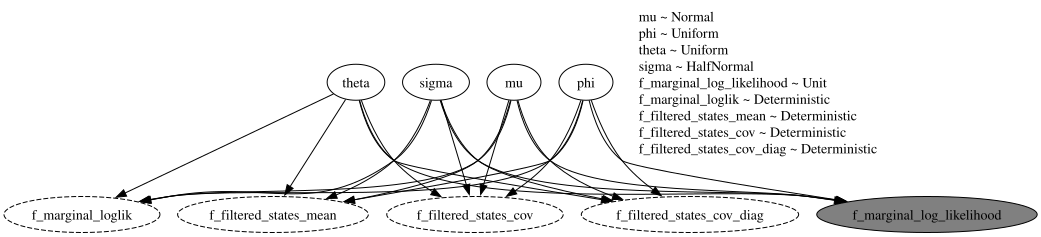

In [28]:
with kalman:
    graph = numpyro.render_model(
        arma_ssm, model_args=(arma_covariates, arma_data), render_distributions=True
    )

graph

As for the local level, the filter integrates the state out: the four parameters feed the factor `f_marginal_log_likelihood`, and the graph has no `time` plate.

`arma_ssoe` is the model of the ARMA example:

In [29]:
def arma_ssoe(covariates: Array, data: Array | None = None) -> None:
    """ARMA(1,1) in innovations form with ``ssoe``."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :]
    mu = numpyro.sample("mu", dist.Normal(loc=0, scale=1))
    phi = numpyro.sample("phi", dist.Uniform(low=-1, high=1))
    theta = numpyro.sample("theta", dist.Uniform(low=-1, high=1))
    sigma = numpyro.sample("sigma", dist.HalfNormal(scale=1))

    def mean(carry: tuple[Array, Array], _: Array | None) -> Array:
        y_prev, error_prev = carry
        return mu + phi * y_prev + theta * error_prev

    def update(
        carry: tuple[Array, Array], y_t: Array, eps_t: Array, _: Array | None
    ) -> tuple[Array, Array]:
        return y_t, eps_t

    result = ssoe(h, "eps", y, (mu[None], jnp.zeros((1,))), mean, update, dist.Normal(0, sigma))
    numpyro.sample("obs", dist.Normal(loc=result.mu, scale=sigma), obs=h.data)
    if h.future > 0:
        numpyro.deterministic("forecast", result.y_future)

It has no `dynestyx` site, so we render it without a handler:

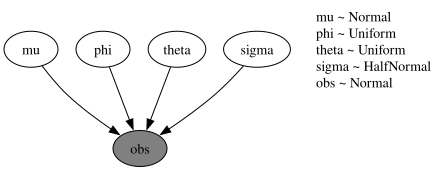

In [30]:
numpyro.render_model(arma_ssoe, model_args=(arma_covariates, arma_data), render_distributions=True)

The four parameters enter the likelihood of the observed `obs` site directly, through the `ssoe` recursion.

The `dynestyx` fit runs under the Kalman filter of the local level section.

In [31]:
rng_key, key_arma_kalman, key_arma_ssoe = random.split(rng_key, 3)

with kalman:
    mcmc_arma_kalman, seconds = fit_nuts(
        key_arma_kalman,
        arma_ssm,
        arma_covariates,
        arma_data,
        num_warmup=1_000,
        chain_method="parallel",
    )

arma_fits = {"dynestyx Kalman filter": diagnostics(mcmc_arma_kalman, seconds)}

mcmc_arma_ssoe, seconds = fit_nuts(
    key_arma_ssoe, arma_ssoe, arma_covariates, arma_data, num_warmup=1_000, chain_method="parallel"
)
arma_fits["ssoe"] = diagnostics(mcmc_arma_ssoe, seconds)

fits_table(arma_fits)

fit,parameters,min bulk ESS,max R-hat,divergences,leapfrog steps per draw,wall time (s)
str,i64,i64,f64,i64,f64,f64
"""dynestyx Kalman filter""",4,3633,1.003,0,6.2,7.8
"""ssoe""",4,3476,1.0,0,6.0,0.8


Both fits converge (largest $\hat{R}$ $1.003$, smallest bulk ESS $3{,}476$, no divergent transitions), with about six leapfrog steps per draw each: neither model samples a path.

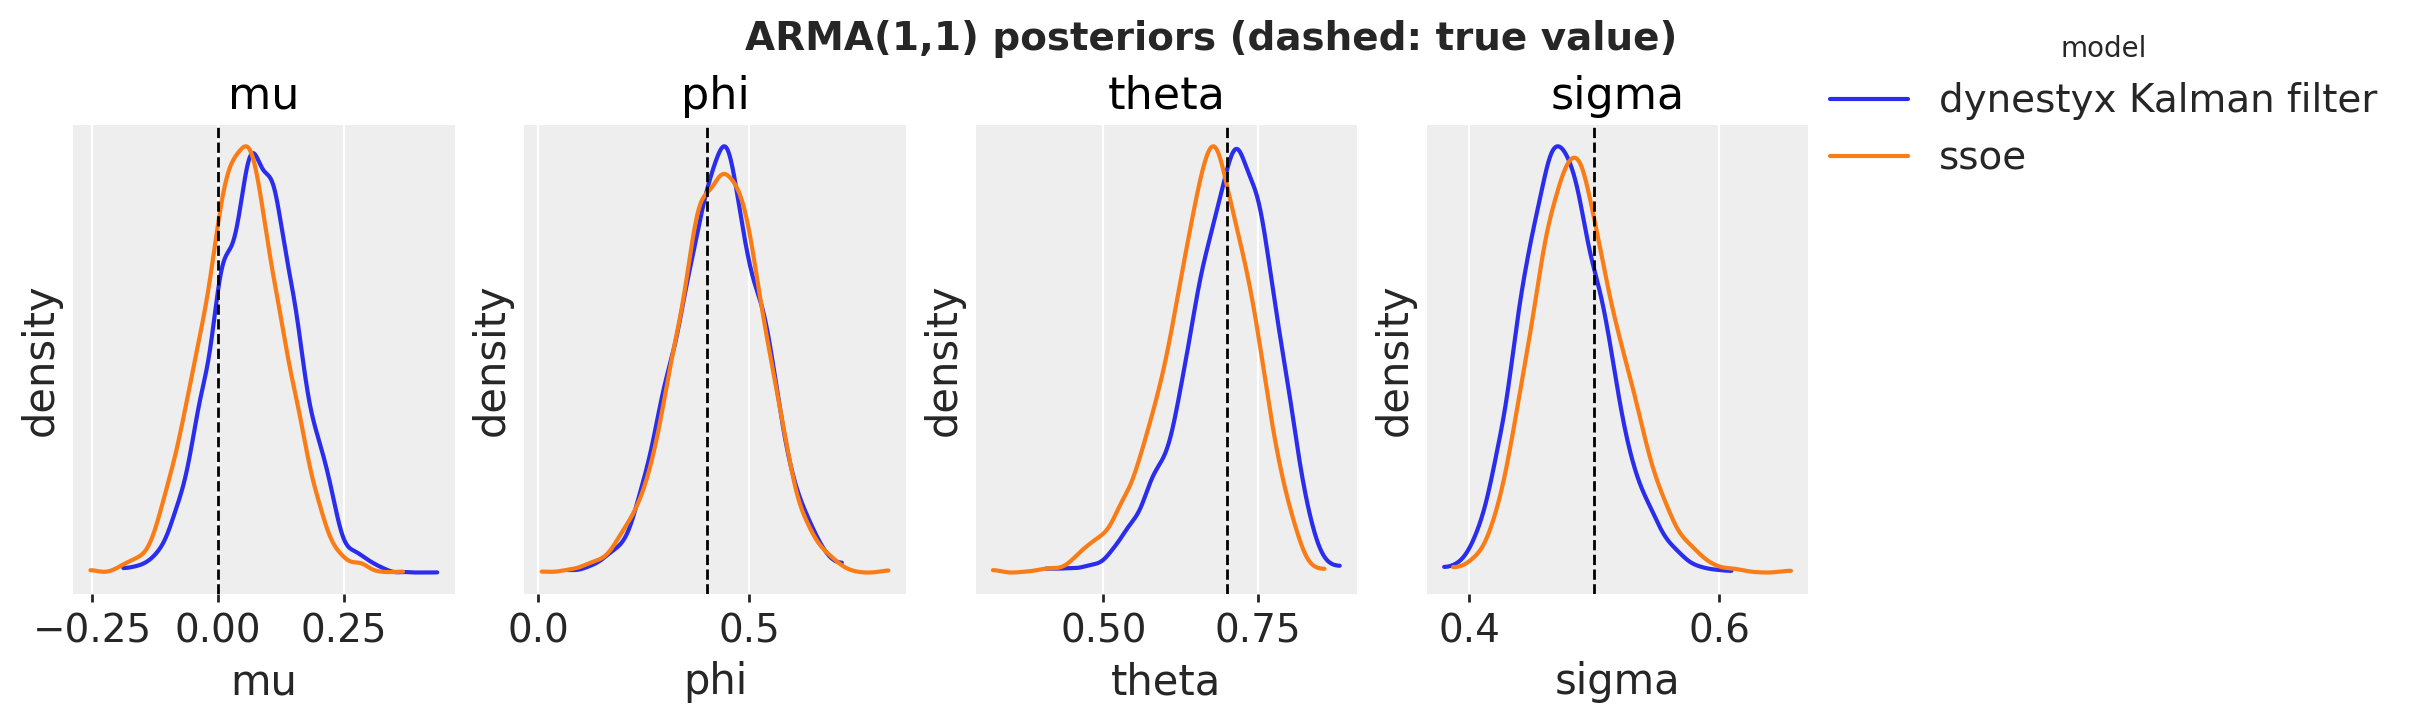

In [32]:
plot_posteriors(
    {"dynestyx Kalman filter": mcmc_arma_kalman, "ssoe": mcmc_arma_ssoe},
    ["mu", "phi", "theta", "sigma"],
    title="ARMA(1,1) posteriors (dashed: true value)",
    truth={"mu": 0.0, "phi": phi_true, "theta": theta_true, "sigma": noise_scale},
)

The two posteriors are close, and the true values lie inside the bulk of both. The `ssoe` likelihood conditions on $y_{-1} = \mu$ and $\varepsilon_{-1} = 0$, and the Kalman filter likelihood is exact up to the small jitter. The small differences between the two posteriors can come from these two likelihoods or from Monte Carlo error, and this run does not separate the two.

## Conclusion

### Key Findings

- **One model function, any handler.** `state_space` turns a `DynamicalModel` into a `numpyro_forecast` model. The handler around each call selects the inference: a Kalman filter or smoother integrates the level out, a `LatentPathBuilder` samples it. `forecast`, `predict_in_sample` and `to_datatree` work unchanged with the handler around the call, and the block raises an error when the handler is missing.
- **The Kalman filter integrates the level out.** For the Normal model it gives the same posteriors and the same in-sample and test CRPS as `innovations`, with $55$ parameters for NUTS instead of $472$. A Kalman smoother exports the filter fit with `to_datatree`, without a refit.
- **The explicit path covers Student-T noise and gaps.** Its posteriors and forecast match `innovations`, but it samples the states in centered form and needs longer chains. The fit through the gap nearly converges.
- **The Kalman filter gives the exact ARMA(1,1) likelihood**, up to a small jitter. Its posteriors are close to those of the `ssoe` model of the ARMA example.

### Limitations

- The in-sample draws under a smoother are independent across weeks. For joint paths, use `innovations` or a `LatentPathBuilder`.
- The `LatentPathBuilder` has no reparameterization option, and every later call must use the builder instance of the fit. Parallel chains under it crashed the process with Python $3.14$ on the machine that executed this notebook.
- The block models one series per model function, with the step index as its time grid.

### Next Steps

The [advanced `dynestyx` example](dynestyx_integration.html) compares filtering and smoothing on a local level model and measures the cost of a full evaluation against a gradient. It also fits a seasonal model with SVI and backtests a `dynestyx` model with expanding windows.